# EDA — Inclusion financière en Afrique de l'Est

Ce notebook suit l'ordre de l'analyse : qualité des données, univarié, cohérence entre pays, bivarié, multivarié, décisions. Les constats portent uniquement sur ce jeu de données. Ils décrivent des associations, pas des causes.

**À partir de la section 3.8, la Tanzanie est corrigée en supposant vraie notre hypothèse d'inversion des libellés.** Aucune documentation du jeu de données ne confirme cette hypothèse.

## 1. Qualité des données

Aucune ligne n'est modifiée ici : cette section ne fait que constater.

In [1]:
import pandas as pd

pd.set_option("display.max_columns", 50)

train = pd.read_csv("../data/original/Train.csv")
test = pd.read_csv("../data/original/Test.csv")
train["compte"] = (train["bank_account"] == "Yes").astype(int)

ordre_pays = ["Kenya", "Rwanda", "Tanzania", "Uganda"]

print("Train :", train.shape, "| Test :", test.shape)
print("Taux de comptes :", round(train["compte"].mean(), 4))

Train : (23524, 14) | Test : (10086, 12)
Taux de comptes : 0.1408


### 1.1 Structure

In [2]:
descripteurs = [col for col in test.columns if col != "uniqueid"]
memes_profils = train.groupby(descripteurs)["compte"].transform("nunique") > 1

pd.Series({
    "valeurs manquantes (train)": train.isna().sum().sum(),
    "valeurs manquantes (test)": test.isna().sum().sum(),
    "doublons (pays, uniqueid)": train.duplicated(["country", "uniqueid"]).sum(),
    "profils répétés, identifiant exclu": train.duplicated(descripteurs).sum(),
    "lignes au profil identique mais à la cible opposée": memes_profils.sum(),
    "personnes communes au train et au test": len(train.merge(test, on=["country", "uniqueid"])),
})

valeurs manquantes (train)                               0
valeurs manquantes (test)                                0
doublons (pays, uniqueid)                                0
profils répétés, identifiant exclu                    4913
lignes au profil identique mais à la cible opposée    1746
personnes communes au train et au test                   0
dtype: int64

Il n'y a aucune valeur manquante, aucun doublon d'identifiant dans un même pays, et aucune personne commune au train et au test. L'imputation n'est donc pas nécessaire.

1 746 lignes (7,4 %) ont un profil identique à une autre ligne, mais une cible opposée. Aucune variable disponible ne peut les séparer.

## 2. Analyse univariée

Chaque variable est décrite seule, sur les données brutes : `location_type` et `marital_status` n'ont pas encore été corrigés. Leur distribution corrigée est donnée en section 3.8. Les outils ci-dessous servent à toute la suite de l'analyse.

In [3]:
import itertools
import sys

import matplotlib.pyplot as plt
import numpy as np
import prince
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

sys.path.insert(0, "..")
from src.preparation import corriger_tanzanie, regrouper_rares

BLEU, ORANGE, VERT, JAUNE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TEXTE, TEXTE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COULEUR_PAYS = dict(zip(ordre_pays, [BLEU, ORANGE, VERT, JAUNE]))
RAMPE = LinearSegmentedColormap.from_list("rampe", ["#f3f7fc", BLEU, "#123a6b"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 9,
})

numeriques = ["age_of_respondent", "household_size"]
categorielles = [
    "country", "location_type", "cellphone_access", "gender_of_respondent",
    "relationship_with_head", "marital_status", "education_level", "job_type",
]
noms = {
    "compte": "Compte bancaire", "country": "Pays", "location_type": "Lieu", "cellphone_access": "Téléphone",
    "gender_of_respondent": "Genre", "relationship_with_head": "Lien au chef", "marital_status": "Statut marital",
    "education_level": "Éducation", "job_type": "Emploi", "age_of_respondent": "Âge", "household_size": "Taille du ménage",
}


def v_cramer(tableau):
    """V de Cramér avec correction de biais (Bergsma), plus part des effectifs attendus sous 5."""
    khi2, p, ddl, attendus = stats.chi2_contingency(tableau, correction=False)
    n = tableau.values.sum()
    lignes, colonnes = tableau.shape
    phi2 = max(0, khi2 / n - (lignes - 1) * (colonnes - 1) / (n - 1))
    l_corr = lignes - (lignes - 1) ** 2 / (n - 1)
    c_corr = colonnes - (colonnes - 1) ** 2 / (n - 1)
    return khi2, p, ddl, np.sqrt(phi2 / min(l_corr - 1, c_corr - 1)), (attendus < 5).mean()


def rapport(tableau):
    return tableau[0, 0] * tableau[1, 1] / (tableau[0, 1] * tableau[1, 0]) if tableau.min() > 0 else np.nan


def tableau_2x2(donnees, variable, modalite):
    return pd.crosstab(donnees[variable] == modalite, donnees["compte"]).reindex(
        index=[True, False], columns=[1, 0], fill_value=0).to_numpy()


def stratifier(donnees, variable, modalite, strates):
    """Odds ratio brut, odds ratio de Mantel-Haenszel, test CMH et test d'homogénéité de Breslow-Day."""
    tableaux = [tableau_2x2(g, variable, modalite) for _, g in donnees.groupby(strates, observed=True)]
    tableaux = [t for t in tableaux if t.sum(axis=0).min() > 0 and t.sum(axis=1).min() > 0]
    table = StratifiedTable(tableaux)
    return {
        "or_brut": rapport(tableau_2x2(donnees, variable, modalite)), "or_mh": table.oddsratio_pooled,
        "ic_bas": table.oddsratio_pooled_confint()[0], "ic_haut": table.oddsratio_pooled_confint()[1],
        "p_cmh": table.test_null_odds().pvalue, "p_homogeneite": table.test_equal_odds().pvalue, "strates": len(tableaux),
    }


### 2.1 Inventaire des 13 colonnes

In [4]:
pd.DataFrame({
    "type": ["identifiant", "cible", "catégorielle", "numérique", "catégorielle", "catégorielle", "catégorielle",
             "catégorielle", "catégorielle", "numérique", "numérique", "catégorielle", "catégorielle"],
}, index=["uniqueid", "bank_account", "country", "year", "location_type", "cellphone_access", "gender_of_respondent",
          "relationship_with_head", "marital_status", "age_of_respondent", "household_size", "education_level", "job_type"]
).assign(modalites=lambda t: [train[v].nunique() for v in t.index])

,type,modalites
uniqueid,identifiant,8735
bank_account,cible,2
country,catégorielle,4
year,numérique,3
location_type,catégorielle,2
cellphone_access,catégorielle,2
gender_of_respondent,catégorielle,2
relationship_with_head,catégorielle,6
marital_status,catégorielle,5
age_of_respondent,numérique,85


`uniqueid` n'est qu'un identifiant : il n'a pas de distribution à analyser, et il n'est pas gardé comme variable.

### 2.2 Cible : `bank_account`

In [5]:
oui = train["compte"].sum()
bas, haut = proportion_confint(oui, len(train), method="wilson")

display(train["bank_account"].value_counts().to_frame("effectif").assign(
    part=lambda t: (t["effectif"] / len(train)).round(4)))
print(f"Part de Yes : {oui / len(train):.2%} (IC à 95 % : {bas:.2%} à {haut:.2%})")
print(f"Rapport No/Yes : {(len(train) - oui) / oui:.1f} pour 1")

,effectif,part
bank_account,,
No,20212,0.8592
Yes,3312,0.1408


Part de Yes : 14.08% (IC à 95 % : 13.64% à 14.53%)
Rapport No/Yes : 6.1 pour 1


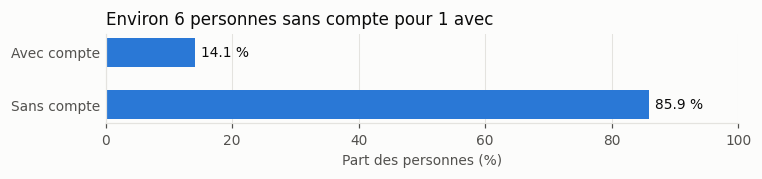

In [6]:
parts = train["bank_account"].value_counts(normalize=True).loc[["No", "Yes"]] * 100

fig, ax = plt.subplots(figsize=(7, 1.7))
ax.barh(["Sans compte", "Avec compte"], parts.values, color=BLEU, height=0.55)
for position, valeur in enumerate(parts.values):
    ax.text(valeur + 1, position, f"{valeur:.1f} %", va="center", color=TEXTE)
ax.set_xlim(0, 100)
ax.set_xlabel("Part des personnes (%)")
ax.set_title("Environ 6 personnes sans compte pour 1 avec")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()

Seulement 14,08 % des personnes ont un compte, soit environ 6 personnes sans compte pour 1 avec. La cible est donc déséquilibrée.

### 2.3 Année : `year`

In [7]:
train.groupby("year").agg(lignes=("compte", "size"), pays=("country", "unique"))

,lignes,pays
year,,
2016,8735,[Rwanda]
2017,6620,[Tanzania]
2018,8169,"[Kenya, Uganda]"


`year` ne fait que recopier le pays : chaque pays n'a qu'une année, et elle n'apporte aucune information propre.

### 2.4 Variables numériques : `age_of_respondent` et `household_size`

In [8]:
def resumer(serie, serie_test):
    q1, q3 = serie.quantile([0.25, 0.75])
    ecart = q3 - q1
    return {
        "moyenne": serie.mean(), "mediane": serie.median(), "ecart_type": serie.std(),
        "min": serie.min(), "q1": q1, "q3": q3, "max": serie.max(),
        "asymetrie": serie.skew(), "aplatissement": serie.kurt(),
        "borne_haute_iqr": q3 + 1.5 * ecart,
        "lignes_au_dela": int((serie > q3 + 1.5 * ecart).sum()),
        "p_normalite": stats.normaltest(serie).pvalue,
        "p_ks_train_test": stats.ks_2samp(serie, serie_test).pvalue,
    }


pd.DataFrame({v: resumer(train[v], test[v]) for v in numeriques}).round(3)

,age_of_respondent,household_size
moyenne,38.805,3.797
mediane,35.000,3.000
ecart_type,16.521,2.228
min,16.000,1.000
q1,26.000,2.000
q3,49.000,5.000
max,100.000,21.000
asymetrie,0.842,0.988
aplatissement,0.100,1.313
borne_haute_iqr,83.500,9.500


Les deux distributions sont asymétriques à droite et ne sont pas normales. Le test de normalité rejette très nettement, mais avec 23 524 lignes il rejetterait presque tout : c'est la forme observée qui compte ici. Les tests suivants seront donc d'abord non paramétriques.

Les valeurs au-delà de la borne IQR ne sont pas aberrantes : 100 ans ou 21 personnes dans un ménage restent possibles, et aucun âge n'est sous 16 ans.

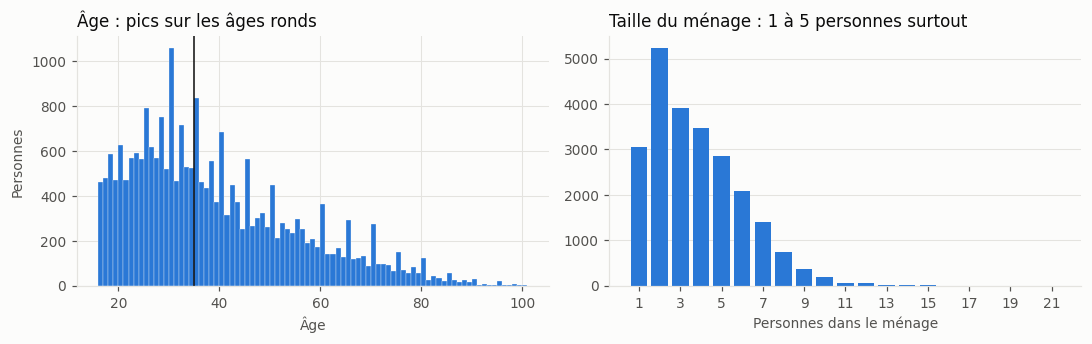

Âges multiples de 5 : 28.1% (20 % attendus si les âges étaient réguliers)
BinomTestResult(k=6616, n=23524, alternative='two-sided', statistic=0.2812446862778439, pvalue=1.6802138689785805e-195)


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))

axes[0].hist(train["age_of_respondent"], bins=range(16, 102), color=BLEU, edgecolor=FOND, linewidth=0.2)
axes[0].axvline(train["age_of_respondent"].median(), color=TEXTE, linewidth=1)
axes[0].set_title("Âge : pics sur les âges ronds")
axes[0].set_xlabel("Âge")
axes[0].set_ylabel("Personnes")

tailles = train["household_size"].value_counts().sort_index()
axes[1].bar(tailles.index, tailles.values, color=BLEU, width=0.8)
axes[1].set_title("Taille du ménage : 1 à 5 personnes surtout")
axes[1].set_xlabel("Personnes dans le ménage")
axes[1].set_xticks(range(1, 22, 2))
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

part_ronde = (train["age_of_respondent"] % 5 == 0).mean()
print(f"Âges multiples de 5 : {part_ronde:.1%} (20 % attendus si les âges étaient réguliers)")
print(stats.binomtest(int((train["age_of_respondent"] % 5 == 0).sum()), len(train), 0.2))

L'âge présente un arrondi net : 28,1 % des âges sont multiples de 5, contre 20 % attendus. L'âge est donc mesuré avec une petite erreur, et deux âges proches ne doivent pas être sur-interprétés.

### 2.5 Variables catégorielles et stabilité entre train et test

La colonne `p_train_test` compare chaque distribution entre les deux fichiers.

In [10]:
lignes = []
for variable in categorielles:
    parts = train[variable].value_counts(normalize=True)
    tableau = pd.concat([train[variable].value_counts(), test[variable].value_counts()], axis=1).fillna(0)
    lignes.append({
        "variable": variable, "modalites": len(parts), "dominante": parts.index[0], "part_dominante": parts.iloc[0],
        "plus_rare": parts.index[-1], "part_rare": parts.iloc[-1], "modalites_sous_1_pct": int((parts < 0.01).sum()),
        "p_train_test": stats.chi2_contingency(tableau)[1],
    })

pd.DataFrame(lignes).set_index("variable").round(4)

,modalites,dominante,part_dominante,plus_rare,part_rare,modalites_sous_1_pct,p_train_test
variable,,,,,,,
country,4,Rwanda,0.3713,Uganda,0.0893,0,1.0000
location_type,2,Rural,0.6097,Urban,0.3903,0,0.5088
cellphone_access,2,Yes,0.7420,No,0.2580,0,0.1531
gender_of_respondent,2,Female,0.5899,Male,0.4101,0,0.0841
relationship_with_head,6,Head of Household,0.5454,Other non-relatives,0.0081,1,0.5354
marital_status,5,Married/Living together,0.4569,Dont know,0.0003,1,0.3706
education_level,6,Primary education,0.5437,Other/Dont know/RTA,0.0015,1,0.1739
job_type,10,Self employed,0.2736,Dont Know/Refuse to answer,0.0054,1,0.9105


Aucune variable catégorielle ne diffère significativement entre train et test. Pour l'âge, le test KS donne p = 0,021, mais ce résultat ne survit pas à une correction sur les 10 comparaisons (0,021 x 10 = 0,21), et l'écart de moyenne n'est que de 0,5 an. Les deux fichiers semblent donc issus de la même population.

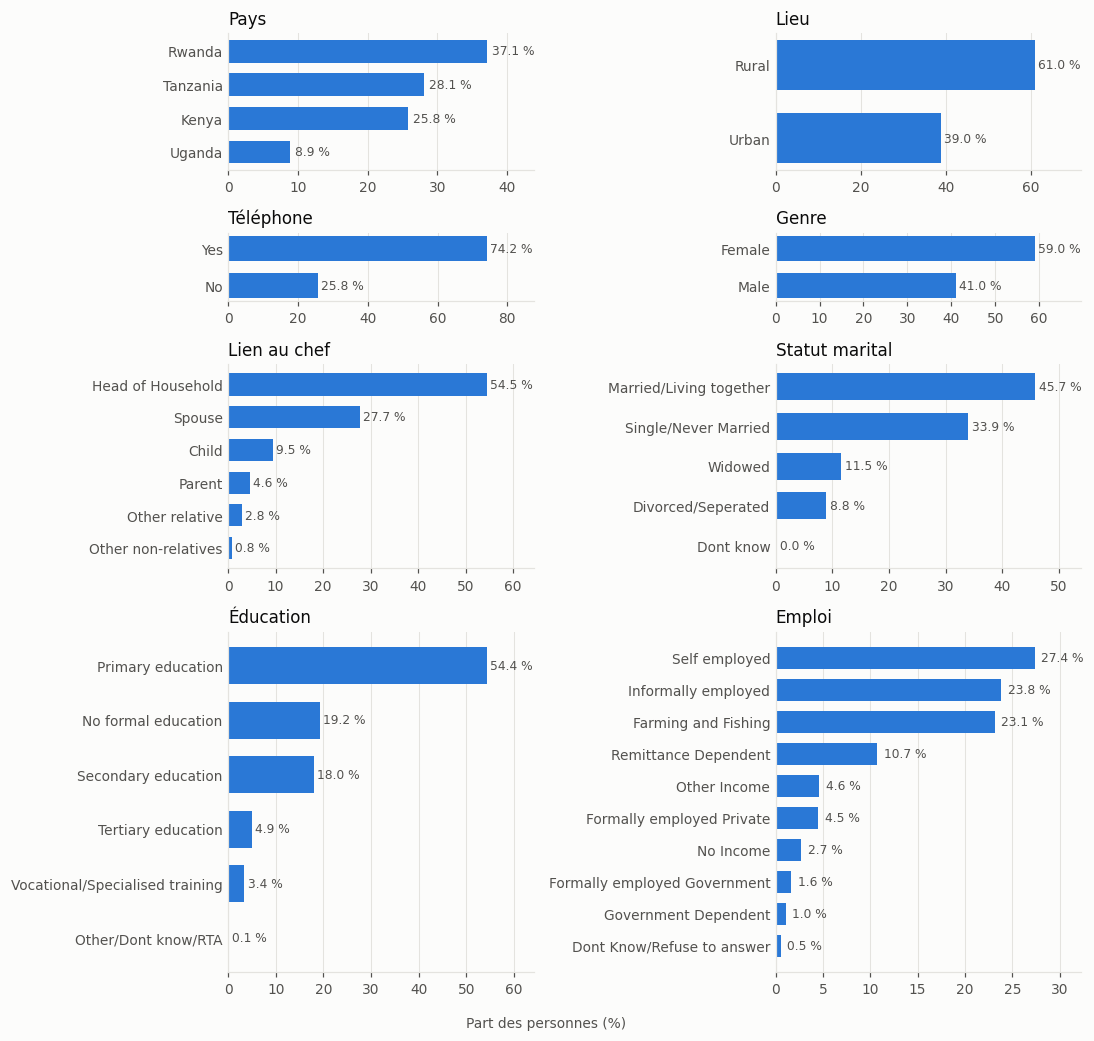

In [11]:
fig, axes = plt.subplots(4, 2, figsize=(10, 9.5), gridspec_kw={"height_ratios": [4, 2, 6, 10]})

for variable, ax in zip(categorielles, axes.ravel()):
    parts = train[variable].value_counts(normalize=True).sort_values()
    ax.barh(parts.index.astype(str), parts.values * 100, color=BLEU, height=0.68)
    for y, valeur in enumerate(parts.values * 100):
        ax.text(valeur + 0.7, y, f"{valeur:.1f} %", va="center", color=TEXTE_2, fontsize=8)
    ax.set_title(noms[variable])
    ax.set_xlim(0, parts.max() * 118)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)

fig.supxlabel("Part des personnes (%)", color=TEXTE_2, fontsize=9)
fig.tight_layout()
plt.show()

Quatre variables ont une modalité sous 1 % : `Dont know` (8 lignes), `Other/Dont know/RTA` (35), `Other non-relatives` (190) et `Dont Know/Refuse to answer` (126). Une estimation sur ces groupes sera instable.

### 2.6 Composition par genre

In [12]:
femmes = (train["gender_of_respondent"] == "Female").sum()
print(stats.binomtest(int(femmes), len(train), 0.5))
print("Part de femmes par pays :")
print(train.groupby("country")["gender_of_respondent"].apply(lambda s: round((s == "Female").mean(), 3)))

BinomTestResult(k=13877, n=23524, alternative='two-sided', statistic=0.5899081788811427, pvalue=2.9567052212569205e-168)
Part de femmes par pays :
country
Kenya       0.574
Rwanda      0.596
Tanzania    0.575
Uganda      0.659
Name: gender_of_respondent, dtype: float64


Les femmes représentent 59 % de l'échantillon, et leur part dépasse 50 % dans les quatre pays. Ce chiffre décrit l'échantillon : il ne doit pas être lu comme la composition de la population.

## 3. Cohérence entre pays et correction de la Tanzanie

Chaque variable peut sembler normale seule et devenir suspecte une fois comparée d'un pays à l'autre. Cette section fait cette comparaison sur les données brutes, formule une hypothèse, la vérifie sans la cible, puis applique la correction.

`uniqueid` n'est unique qu'à l'intérieur d'un pays, et il ne sert pas de variable.

Les profils répétés ne sont pas forcément des erreurs : avec surtout des variables catégorielles, deux personnes peuvent se ressembler. Les lignes au profil identique mais à la cible opposée fixent une limite : aucune variable du jeu ne peut les départager.

### 3.1 Pays et année

In [13]:
pd.crosstab(train["country"], train["year"])

year,2016,2017,2018
country,,,
Kenya,0,0,6068
Rwanda,8735,0,0
Tanzania,0,6620,0
Uganda,0,0,2101


Chaque pays n'a qu'une année d'enquête : **l'effet du pays et celui de l'année ne peuvent pas être séparés**.

### 3.2 `job_type` : les modalités diffèrent selon les pays

In [14]:
pd.crosstab(train["job_type"], train["country"])[ordre_pays]

country,Kenya,Rwanda,Tanzania,Uganda
job_type,,,,
Dont Know/Refuse to answer,3,56,0,67
Farming and Fishing,1609,3832,0,0
Formally employed Government,260,127,0,0
Formally employed Private,416,161,370,108
Government Dependent,65,91,84,7
Informally employed,1419,2878,1300,0
No Income,0,0,380,247
Other Income,154,323,35,568
Remittance Dependent,1188,662,677,0


Plusieurs modalités n'existent que dans certains pays : aucune ligne `Farming and Fishing` en Tanzanie et en Ouganda, et `No Income` uniquement dans ces deux pays. Comparer `job_type` entre pays revient donc en partie à comparer des codages.

### 3.3 `location_type` : comparaison par pays

In [15]:
train["telephone"] = (train["cellphone_access"] == "Yes").astype(int)
train["apres_primaire"] = train["education_level"].isin([
    "Secondary education", "Tertiary education", "Vocational/Specialised training",
]).astype(int)

par_lieu = train.groupby(["country", "location_type"]).agg(
    effectif=("compte", "size"),
    compte=("compte", "mean"),
    telephone=("telephone", "mean"),
    apres_primaire=("apres_primaire", "mean"),
).round(3)
par_lieu

effectif  compte  telephone  apres_primaire
country  location_type                                             
Kenya    Rural              3543   0.173      0.732           0.312
         Urban              2525   0.359      0.868           0.560
Rwanda   Rural              7483   0.083      0.812           0.158
         Urban              1252   0.308      0.939           0.458
Tanzania Rural              1809   0.207      0.794           0.358
         Urban              4811   0.048      0.524           0.127
Uganda   Rural              1508   0.042      0.641           0.216
         Urban               593   0.197      0.840           0.538

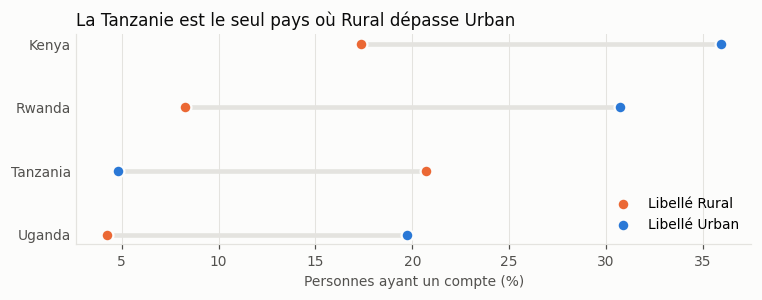

In [16]:
taux_lieu = train.pivot_table(index="country", columns="location_type", values="compte", aggfunc="mean").loc[ordre_pays] * 100
fig, ax = plt.subplots(figsize=(7, 2.8))
positions = range(len(taux_lieu))[::-1]
ax.hlines(positions, taux_lieu["Rural"], taux_lieu["Urban"], color=GRILLE, linewidth=3, zorder=1)
ax.scatter(taux_lieu["Rural"], positions, color=ORANGE, s=60, zorder=3, label="Libellé Rural", edgecolor=FOND, linewidth=1.5)
ax.scatter(taux_lieu["Urban"], positions, color=BLEU, s=60, zorder=3, label="Libellé Urban", edgecolor=FOND, linewidth=1.5)
ax.set_yticks(list(positions), taux_lieu.index)
ax.set_xlabel("Personnes ayant un compte (%)")
ax.set_title("La Tanzanie est le seul pays où Rural dépasse Urban")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

Au Kenya, au Rwanda et en Ouganda, les zones `Urban` dépassent les zones `Rural` sur les trois taux. En Tanzanie, c'est l'inverse sur les trois, et 73 % des lignes sont `Urban`.

**Notre hypothèse, partie lieu :** les libellés `Rural` et `Urban` pourraient être inversés en Tanzanie.

### 3.4 `marital_status` : comparaison par pays

In [17]:
statut_pct = pd.crosstab(train["marital_status"], train["country"], normalize="columns")[ordre_pays].round(3)
statut_age = train.pivot_table(index="marital_status", columns="country", values="age_of_respondent", aggfunc="median")[ordre_pays]
conjoints = train[train["relationship_with_head"] == "Spouse"]
conjoints_statut = pd.crosstab(conjoints["marital_status"], conjoints["country"])[ordre_pays]

display(statut_pct, statut_age, conjoints_statut)

country,Kenya,Rwanda,Tanzania,Uganda
marital_status,,,,
Divorced/Seperated,0.058,0.054,0.163,0.079
Dont know,0.001,0.000,0.000,0.000
Married/Living together,0.581,0.595,0.101,0.649
Single/Never Married,0.249,0.214,0.639,0.180
Widowed,0.111,0.137,0.097,0.091


country,Kenya,Rwanda,Tanzania,Uganda
marital_status,,,,
Divorced/Seperated,40.0,41.0,21.0,37.0
Dont know,35.5,NaN,NaN,NaN
Married/Living together,38.0,36.0,40.0,32.0
Single/Never Married,22.0,21.0,35.0,21.0
Widowed,64.0,60.0,60.0,58.5


country,Kenya,Rwanda,Tanzania,Uganda
marital_status,,,,
Divorced/Seperated,0,4,3,0
Married/Living together,1412,2517,2,731
Single/Never Married,31,16,1799,1
Widowed,0,4,0,0


En Tanzanie, 1 799 conjoints du chef de ménage sont déclarés `Single/Never Married`, et seulement 2 `Married/Living together`. Les âges médians ne suivent pas non plus le schéma des autres pays : `Divorced/Seperated` y a 21 ans, comme `Single/Never Married` ailleurs.

**Notre hypothèse, partie statut :** les libellés pourraient être permutés en Tanzanie (`Single` pour marié, `Divorced` pour célibataire, `Married` pour divorcé).

### 3.5 `education_level` et `relationship_with_head` : comparaison par pays

In [18]:
taux_education = train.pivot_table(index="education_level", columns="country", values="compte", aggfunc="mean")[ordre_pays].round(3)
effectif_education = pd.crosstab(train["education_level"], train["country"])[ordre_pays]
age_relation = train.pivot_table(index="relationship_with_head", columns="country", values="age_of_respondent", aggfunc="median")[ordre_pays]
effectif_relation = pd.crosstab(train["relationship_with_head"], train["country"])[ordre_pays]

display(taux_education, effectif_education, age_relation, effectif_relation)

country,Kenya,Rwanda,Tanzania,Uganda
education_level,,,,
No formal education,0.086,0.036,0.013,0.013
Other/Dont know/RTA,0.750,0.222,0.333,0.000
Primary education,0.155,0.090,0.052,0.034
Secondary education,0.307,0.223,0.083,0.130
Tertiary education,0.747,0.768,0.323,0.781
Vocational/Specialised training,0.600,0.231,0.731,0.475


country,Kenya,Rwanda,Tanzania,Uganda
education_level,,,,
No formal education,941,2122,1133,319
Other/Dont know/RTA,8,18,3,6
Primary education,2600,4836,4224,1131
Secondary education,1785,1491,433,514
Tertiary education,292,177,656,32
Vocational/Specialised training,442,91,171,99


country,Kenya,Rwanda,Tanzania,Uganda
relationship_with_head,,,,
Child,20.0,20.0,22.0,20.0
Head of Household,42.0,43.0,41.0,38.0
Other non-relatives,23.0,20.0,20.0,20.5
Other relative,22.0,20.0,22.0,20.0
Parent,30.0,21.0,21.0,19.0
Spouse,34.0,34.0,32.0,30.0


country,Kenya,Rwanda,Tanzania,Uganda
relationship_with_head,,,,
Child,775,1214,199,41
Head of Household,3535,4575,3697,1024
Other non-relatives,37,86,47,20
Other relative,250,88,237,93
Parent,28,231,636,191
Spouse,1443,2541,1804,732


Deux signaux plus faibles sont à garder en tête :

- En Tanzanie, `Tertiary education` a un taux de comptes de 32 %, contre 75 à 78 % ailleurs, et `Vocational/Specialised training` passe à 73 %.
- Hors Kenya, l'âge médian de la modalité `Parent` est d'environ 20 ans. Le sens de cette modalité reste à clarifier.

### 3.6 Le test suit-il le même schéma ?

In [19]:
lieu_test = pd.crosstab(test["location_type"], test["country"], normalize="columns")[ordre_pays].round(3)
statut_test = pd.crosstab(test["marital_status"], test["country"], normalize="columns")[ordre_pays].round(3)

display(lieu_test, statut_test)

country,Kenya,Rwanda,Tanzania,Uganda
location_type,,,,
Rural,0.582,0.856,0.283,0.738
Urban,0.418,0.144,0.717,0.262


country,Kenya,Rwanda,Tanzania,Uganda
marital_status,,,,
Divorced/Seperated,0.057,0.047,0.169,0.070
Dont know,0.000,0.000,0.000,0.000
Married/Living together,0.587,0.619,0.088,0.632
Single/Never Married,0.258,0.203,0.647,0.199
Widowed,0.097,0.131,0.097,0.100


Le fichier de test présente le même schéma en Tanzanie. La correction doit donc s'appliquer aux deux fichiers.

### 3.7 Vérification de l'hypothèse sans utiliser la cible

Si les libellés de Tanzanie sont faux, les corriger doit rapprocher ce pays des autres, sans qu'on utilise le compte bancaire.

In [20]:
corrige = corriger_tanzanie(train)

paires_coherence = [
    ("country", "marital_status"), ("country", "location_type"), ("location_type", "marital_status"),
    ("relationship_with_head", "marital_status"), ("location_type", "cellphone_access"), ("location_type", "education_level"),
]
display(pd.DataFrame([
    {"paire": f"{a} x {b}", "V_brut": v_cramer(pd.crosstab(train[a], train[b]))[3], "V_recode": v_cramer(pd.crosstab(corrige[a], corrige[b]))[3]}
    for a, b in paires_coherence
]).round(3))

conjoints_recodes = corrige[corrige["relationship_with_head"] == "Spouse"]
print("Conjoints déclarés mariés :", round((conjoints["marital_status"] == "Married/Living together").mean(), 3),
      "->", round((conjoints_recodes["marital_status"] == "Married/Living together").mean(), 3))
display(corrige.pivot_table(index="marital_status", columns="country", values="age_of_respondent", aggfunc="median")[ordre_pays])
corrige.groupby("country")["location_type"].apply(lambda s: round((s == "Rural").mean(), 3)).to_frame("part_rural")

,paire,V_brut,V_recode
0,country x marital_status,0.284,0.071
1,country x location_type,0.484,0.243
2,location_type x marital_status,0.284,0.148
3,relationship_with_head x marital_status,0.298,0.403
4,location_type x cellphone_access,0.085,0.158
5,location_type x education_level,0.132,0.322


Conjoints déclarés mariés : 0.715 -> 0.991


country,Kenya,Rwanda,Tanzania,Uganda
marital_status,,,,
Divorced/Seperated,40.0,41.0,40.0,37.0
Dont know,35.5,NaN,NaN,NaN
Married/Living together,38.0,36.0,35.0,32.0
Single/Never Married,22.0,21.0,21.0,21.0
Widowed,64.0,60.0,60.0,58.5


,part_rural
country,
Kenya,0.584
Rwanda,0.857
Tanzania,0.727
Uganda,0.718


La correction rend les données nettement plus cohérentes, sans que la cible intervienne :

- 99,1 % des conjoints sont désormais mariés, contre 71,5 % avant.
- Les âges médians de la Tanzanie (40, 35, 21 et 60 ans) rejoignent ceux des autres pays, et 72,7 % de ses lignes deviennent rurales, comme en Ouganda.
- Le lien entre pays et statut marital tombe de 0,28 à 0,07, et celui entre pays et lieu de 0,48 à 0,24.
- Le lien entre lieu et éducation monte de 0,13 à 0,32, et celui entre lieu et téléphone de 0,09 à 0,16.

**Ces éléments soutiennent fortement notre hypothèse, mais ils ne la prouvent pas** : elle reste une inférence.

### 3.8 Correction de la Tanzanie, en supposant notre hypothèse vraie

La correction est définie une seule fois, dans `src/preparation.py`, et appliquée au train et au test. En Tanzanie, `Rural` et `Urban` sont échangés. `Single/Never Married` devient `Married/Living together`, `Divorced/Seperated` devient `Single/Never Married`, et `Married/Living together` devient `Divorced/Seperated`.

**À partir d'ici, `train` et `test` désignent les données corrigées**, et tous les résultats dépendent de cette hypothèse.

In [21]:
train_brut, test_brut = train, test
train, test = corrige, corriger_tanzanie(test_brut)

display(pd.concat({
    "train brut": train_brut["location_type"].value_counts(normalize=True),
    "train corrigé": train["location_type"].value_counts(normalize=True),
    "test brut": test_brut["location_type"].value_counts(normalize=True),
    "test corrigé": test["location_type"].value_counts(normalize=True),
}, axis=1).round(3))
display(pd.concat({
    "train brut": train_brut["marital_status"].value_counts(normalize=True),
    "train corrigé": train["marital_status"].value_counts(normalize=True),
    "test brut": test_brut["marital_status"].value_counts(normalize=True),
    "test corrigé": test["marital_status"].value_counts(normalize=True),
}, axis=1).round(3))

display(pd.concat({
    "brut": train_brut.groupby("location_type")["compte"].mean(),
    "corrigé": train.groupby("location_type")["compte"].mean(),
}, axis=1).round(3))

pd.DataFrame({
    "brut": stratifier(train_brut, "location_type", "Urban", "country"),
    "corrigé": stratifier(train, "location_type", "Urban", "country"),
}).T.round(4)

,train brut,train corrigé,test brut,test corrigé
location_type,,,,
Rural,0.61,0.737,0.614,0.736
Urban,0.39,0.263,0.386,0.264


,train brut,train corrigé,test brut,test corrigé
marital_status,,,,
Married/Living together,0.457,0.608,0.462,0.620
Single/Never Married,0.339,0.206,0.342,0.207
Widowed,0.115,0.115,0.110,0.110
Divorced/Seperated,0.088,0.071,0.086,0.063
Dont know,0.000,0.000,0.000,0.000


,brut,corrigé
location_type,,
Rural,0.117,0.088
Urban,0.179,0.289


,or_brut,or_mh,ic_bas,ic_haut,p_cmh,p_homogeneite,strates
brut,1.6505,1.7458,1.6177,1.8840,0.0,0.0,4.0
corrigé,4.2018,3.7271,3.4416,4.0364,0.0,0.0,4.0


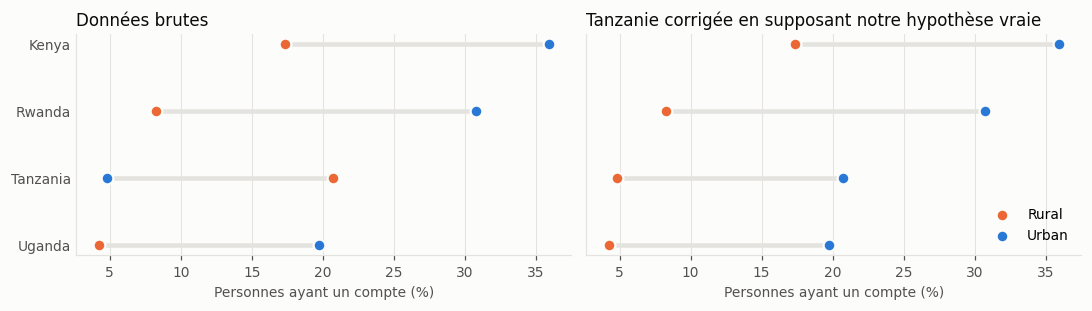

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.9), sharex=True, sharey=True)
for ax, donnees, titre in [(axes[0], train_brut, "Données brutes"), (axes[1], train, "Tanzanie corrigée en supposant notre hypothèse vraie")]:
    taux = donnees.pivot_table(index="country", columns="location_type", values="compte", aggfunc="mean").loc[ordre_pays] * 100
    positions = range(len(taux))[::-1]
    ax.hlines(positions, taux["Rural"], taux["Urban"], color=GRILLE, linewidth=3, zorder=1)
    ax.scatter(taux["Rural"], positions, color=ORANGE, s=60, zorder=3, label="Rural", edgecolor=FOND, linewidth=1.5)
    ax.scatter(taux["Urban"], positions, color=BLEU, s=60, zorder=3, label="Urban", edgecolor=FOND, linewidth=1.5)
    ax.set_yticks(list(positions), taux.index)
    ax.set_title(titre)
    ax.set_xlabel("Personnes ayant un compte (%)")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
axes[1].legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

Sous notre hypothèse, 73,7 % des lignes sont rurales au lieu de 61,0 %, et 60,8 % sont mariées au lieu de 45,7 %. L'écart de taux de comptes entre `Urban` et `Rural` passe de 6 à 20 points, et l'odds ratio à pays fixé de 1,75 à 3,73.

Ce dernier résultat utilise la cible : c'est une conséquence de la correction, pas un argument en sa faveur.

### Bilan

| Constat | Conséquence |
|---|---|
| Pays et année confondus | Ne jamais parler d'un effet de l'année |
| `job_type` codé différemment selon les pays | Comparaisons entre pays à lire avec prudence |
| `location_type` et `marital_status` incohérents en Tanzanie | Corrigés en supposant notre hypothèse vraie |
| `Tertiary` et `Vocational` inhabituels en Tanzanie | Non corrigés : aucune preuve indépendante de la cible |

## 4. Analyse bivariée

**Rappel :** ces résultats supposent vraie notre hypothèse sur les libellés de Tanzanie (section 3.7). Aucune documentation du jeu de données ne la confirme.

### 4.1 Toutes les paires de variables, avec tests

Les 11 variables utiles donnent 55 paires, dont 10 avec la cible. `year` et `uniqueid` sont écartés pour les raisons vues plus haut.

| Paire | Test | Taille d'effet |
|---|---|---|
| catégorielle x catégorielle | khi-deux d'indépendance | V de Cramér corrigé |
| numérique x 2 groupes | Mann-Whitney | corrélation bisériale de rangs |
| numérique x 3 groupes ou plus | Kruskal-Wallis | racine de epsilon² |
| numérique x numérique | Spearman | rho de Spearman |

Comme 55 tests sont faits, les p-values sont corrigées par la méthode de Holm. Une p-value affichée à 0 signifie seulement qu'elle est trop petite pour être représentée.

In [23]:
def tester_paire(donnees, a, b):
    a_num, b_num = a in numeriques, b in numeriques
    if a_num and b_num:
        rho, p = stats.spearmanr(donnees[a], donnees[b])
        return "Spearman", rho, p, abs(rho), "|rho|", 0.0
    if a_num or b_num:
        nombre, groupe = (a, b) if a_num else (b, a)
        groupes = [g[nombre].to_numpy() for _, g in donnees.groupby(groupe)]
        if len(groupes) == 2:
            u, p = stats.mannwhitneyu(groupes[0], groupes[1])
            return "Mann-Whitney", u, p, abs(2 * u / (len(groupes[0]) * len(groupes[1])) - 1), "|r bisérial|", 0.0
        h, p = stats.kruskal(*groupes)
        epsilon2 = max(0, (h - len(groupes) + 1) / (len(donnees) - len(groupes)))
        return "Kruskal-Wallis", h, p, np.sqrt(epsilon2), "racine de epsilon²", 0.0
    khi2, p, _, v, sous_5 = v_cramer(pd.crosstab(donnees[a], donnees[b]))
    return "Khi-deux", khi2, p, v, "V de Cramér", sous_5


variables = ["compte"] + categorielles + numeriques
resultats = pd.DataFrame(
    [(a, b, *tester_paire(train, a, b)) for a, b in itertools.combinations(variables, 2)],
    columns=["variable_1", "variable_2", "test", "statistique", "p", "effet", "mesure", "attendus_sous_5"],
)
resultats["p_holm"] = multipletests(resultats["p"], method="holm")[1]
resultats = resultats.sort_values("effet", ascending=False).reset_index(drop=True)

print(f"{len(resultats)} paires, {(resultats['p_holm'] < 0.05).sum()} significatives au seuil de 5 % après Holm.")
print(resultats["test"].value_counts().to_string())
resultats.round({"statistique": 1, "effet": 3, "attendus_sous_5": 3}).assign(
    p=resultats["p"].map("{:.2e}".format), p_holm=resultats["p_holm"].map("{:.2e}".format))

55 paires, 53 significatives au seuil de 5 % après Holm.
test
Khi-deux          36
Kruskal-Wallis    10
Mann-Whitney       8
Spearman           1


,variable_1,variable_2,test,statistique,p,effet,mesure,attendus_sous_5,p_holm
0,marital_status,age_of_respondent,Kruskal-Wallis,8985.5,0.00e+00,0.618,racine de epsilon²,0.000,0.00e+00
1,relationship_with_head,age_of_respondent,Kruskal-Wallis,7196.9,0.00e+00,0.553,racine de epsilon²,0.000,0.00e+00
2,gender_of_respondent,relationship_with_head,Khi-deux,6100.4,0.00e+00,0.509,V de Cramér,0.000,0.00e+00
3,country,household_size,Kruskal-Wallis,5047.9,0.00e+00,0.463,racine de epsilon²,0.000,0.00e+00
4,country,job_type,Khi-deux,14407.3,0.00e+00,0.451,V de Cramér,0.000,0.00e+00
5,relationship_with_head,marital_status,Khi-deux,15329.5,0.00e+00,0.403,V de Cramér,0.200,0.00e+00
6,compte,education_level,Khi-deux,3549.1,0.00e+00,0.388,V de Cramér,0.083,0.00e+00
7,education_level,age_of_respondent,Kruskal-Wallis,3227.8,0.00e+00,0.370,racine de epsilon²,0.000,0.00e+00
8,compte,job_type,Khi-deux,3032.3,0.00e+00,0.359,V de Cramér,0.000,0.00e+00
9,location_type,education_level,Khi-deux,2444.0,0.00e+00,0.322,V de Cramér,0.000,0.00e+00


**Lecture essentielle : avec 23 524 lignes, presque tout est significatif.** 53 paires sur 55 le sont. La p-value dit qu'un lien existe sans doute, pas qu'il est important : c'est la taille d'effet qu'il faut lire.

### 4.2 Paires non significatives et tests fragiles

In [24]:
non_significatives = resultats[resultats["p_holm"] >= 0.05]
display(non_significatives[["variable_1", "variable_2", "test", "effet", "p_holm"]].round(4))

# Le khi-deux devient fragile quand trop d'effectifs attendus sont faibles : on le refait sans les modalités rares.
fragiles = resultats[resultats["attendus_sous_5"] > 0.2]
sans_rares = []
for _, ligne in fragiles.iterrows():
    tableau = pd.crosstab(train[ligne["variable_1"]], train[ligne["variable_2"]])
    tableau = tableau.loc[tableau.sum(axis=1) >= 50, tableau.sum(axis=0) >= 50]
    khi2, p, _, v, sous_5 = v_cramer(tableau)
    sans_rares.append({"paire": f"{ligne['variable_1']} x {ligne['variable_2']}", "V_avant": round(ligne["effet"], 3),
                       "V_apres": round(v, 3), "p_apres": p, "attendus_sous_5_apres": round(sous_5, 3)})
pd.DataFrame(sans_rares)

,variable_1,variable_2,test,effet,p_holm
53,gender_of_respondent,household_size,Mann-Whitney,0.0136,0.1433
54,location_type,gender_of_respondent,Khi-deux,0.0014,0.3064


,paire,V_avant,V_apres,p_apres,attendus_sous_5_apres
0,marital_status x education_level,0.203,0.235,0.0,0.0


Seules deux paires ne sont pas significatives : le genre n'est lié ni au lieu ni à la taille du ménage.

Une seule paire dépasse 20 % d'effectifs attendus sous 5 : statut marital x éducation. Sans les modalités rares, le test reste très significatif et le V monte de 0,203 à 0,235. La conclusion ne dépend donc pas de ces cellules.

### 4.3 Carte de toutes les associations

Les mesures ne sont pas strictement identiques, mais toutes vont de 0 à 1 et donnent le même ordre de grandeur.

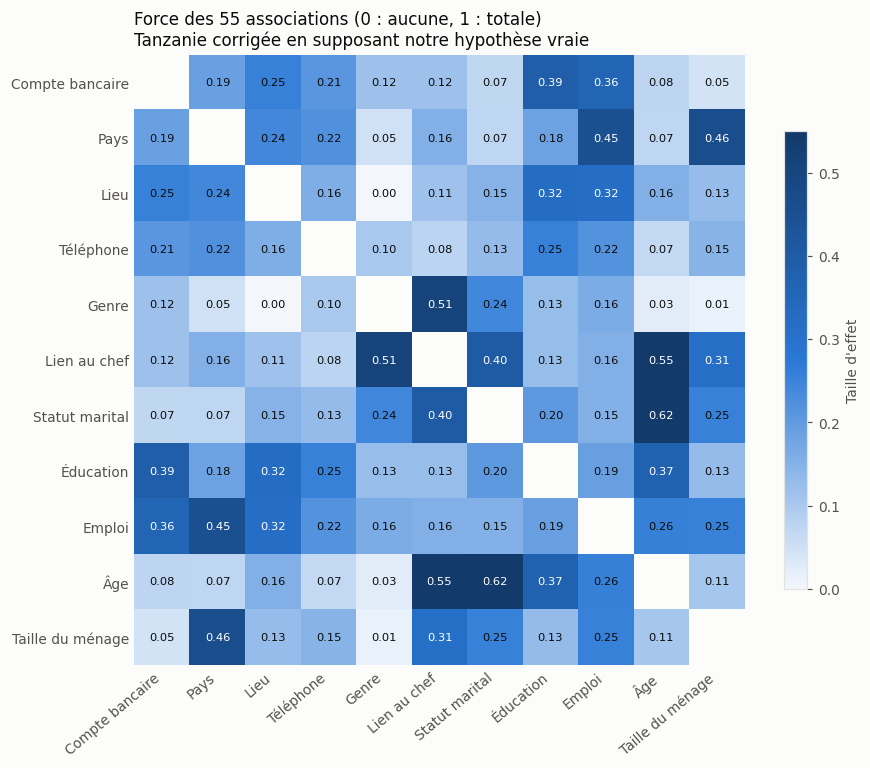

In [25]:
carte = pd.DataFrame(np.nan, index=variables, columns=variables, dtype=float)
for _, ligne in resultats.iterrows():
    carte.loc[ligne["variable_2"], ligne["variable_1"]] = ligne["effet"]
    carte.loc[ligne["variable_1"], ligne["variable_2"]] = ligne["effet"]
carte = carte.rename(index=noms, columns=noms)

fig, ax = plt.subplots(figsize=(8.6, 7))
image = ax.imshow(carte.values, cmap=RAMPE, vmin=0, vmax=0.55)
ax.set_xticks(range(len(carte)), carte.columns, rotation=40, ha="right")
ax.set_yticks(range(len(carte)), carte.index)
ax.grid(False)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
for i, j in itertools.product(range(len(carte)), repeat=2):
    if i != j:
        valeur = carte.values[i, j]
        ax.text(j, i, f"{valeur:.2f}", ha="center", va="center", fontsize=7.5, color="white" if valeur > 0.26 else TEXTE)
ax.set_title("Force des 55 associations (0 : aucune, 1 : totale)\nTanzanie corrigée en supposant notre hypothèse vraie")
fig.colorbar(image, shrink=0.75, label="Taille d'effet")
fig.tight_layout()
plt.show()

Les liens les plus forts entre descripteurs sont statut marital x âge (0,62), lien au chef x âge (0,55), lien au chef x genre (0,51), pays x ménage (0,46), pays x emploi (0,45) et lien au chef x statut marital (0,40).

Plusieurs de ces liens ont une explication simple : un conjoint est le plus souvent une femme, et un enfant du chef est jeune. Le lien entre pays et emploi reflète en partie le codage de `job_type` (section 3.2). Aucune paire n'est assez forte pour rendre une variable redondante.

### 4.4 Chaque variable face à la cible

In [26]:
variables_cible = (
    resultats[(resultats["variable_1"] == "compte") | (resultats["variable_2"] == "compte")]
    .assign(variable=lambda t: t["variable_1"].where(t["variable_1"] != "compte", t["variable_2"]))
    [["variable", "test", "statistique", "p_holm", "effet", "mesure"]]
    .reset_index(drop=True)
)
variables_cible.assign(p_holm=variables_cible["p_holm"].map("{:.2e}".format)).round({"statistique": 1, "effet": 3})

,variable,test,statistique,p_holm,effet,mesure
0,education_level,Khi-deux,3549.1,0.00e+00,0.388,V de Cramér
1,job_type,Khi-deux,3032.3,0.00e+00,0.359,V de Cramér
2,location_type,Khi-deux,1515.9,0.00e+00,0.254,V de Cramér
3,cellphone_access,Khi-deux,1034.1,1.84e-225,0.210,V de Cramér
4,country,Khi-deux,838.0,6.58e-180,0.188,V de Cramér
5,relationship_with_head,Khi-deux,327.9,1.59e-67,0.117,V de Cramér
6,gender_of_respondent,Khi-deux,323.3,4.96e-71,0.117,V de Cramér
7,age_of_respondent,Mann-Whitney,30957246.0,2.33e-11,0.075,|r bisérial|
8,marital_status,Khi-deux,121.5,2.05e-24,0.071,V de Cramér
9,household_size,Mann-Whitney,34980835.0,9.86e-05,0.045,|r bisérial|


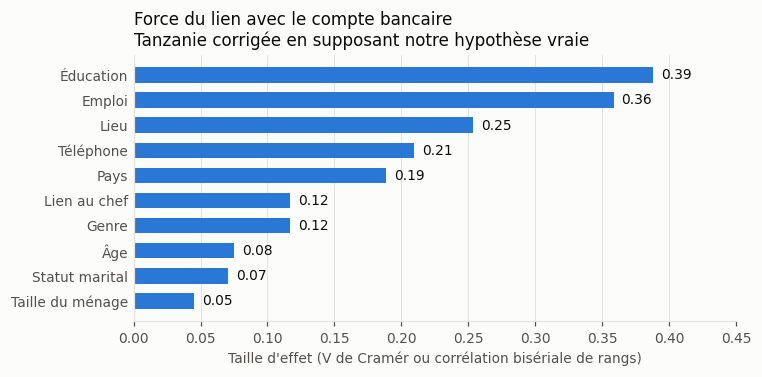

In [27]:
forces = variables_cible.assign(nom=variables_cible["variable"].map(noms)).sort_values("effet")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(forces["nom"], forces["effet"], color=BLEU, height=0.62)
for position, valeur in enumerate(forces["effet"]):
    ax.text(valeur + 0.006, position, f"{valeur:.2f}", va="center", color=TEXTE)
ax.set_xlim(0, 0.45)
ax.set_xlabel("Taille d'effet (V de Cramér ou corrélation bisériale de rangs)")
ax.set_title("Force du lien avec le compte bancaire\nTanzanie corrigée en supposant notre hypothèse vraie")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()

Par force décroissante, la cible est liée à l'éducation (0,39), à l'emploi (0,36), au lieu (0,25), au téléphone (0,21) et au pays (0,19). Viennent ensuite le lien au chef et le genre (0,12), l'âge (0,08), le statut marital (0,07) et la taille du ménage (0,05).

**Sous notre hypothèse, le lieu devient le troisième lien avec la cible**, alors qu'il valait 0,09 sur les données brutes.

Le détail par modalité suit. Un résidu ajusté au-delà de 2 en valeur absolue signale une modalité nettement différente du taux global.

In [28]:
def taux_par_modalite(donnees, variable):
    groupes = donnees.groupby(variable)["compte"].agg(effectif="size", comptes="sum")
    groupes["taux"] = groupes["comptes"] / groupes["effectif"]
    groupes["bas"], groupes["haut"] = proportion_confint(groupes["comptes"], groupes["effectif"], method="wilson")
    global_ = donnees["compte"].mean()
    part = groupes["effectif"] / len(donnees)
    # Résidu ajusté : au-delà de 2 en valeur absolue, la modalité s'écarte nettement du taux global.
    groupes["residu_ajuste"] = (groupes["taux"] - global_) / np.sqrt(
        global_ * (1 - global_) * (1 - part) / groupes["effectif"])
    return groupes.sort_values("taux")


for variable in categorielles:
    print(f"\n{noms[variable]}")
    display(taux_par_modalite(train, variable).drop(columns="comptes").round(3))


Pays


,effectif,taux,bas,haut,residu_ajuste
country,,,,,
Uganda,2101,0.086,0.075,0.099,-7.546
Tanzania,6620,0.092,0.085,0.099,-13.550
Rwanda,8735,0.115,0.108,0.122,-8.800
Kenya,6068,0.251,0.240,0.262,28.565



Lieu


,effectif,taux,bas,haut,residu_ajuste
location_type,,,,,
Rural,17345,0.088,0.084,0.092,-38.935
Urban,6179,0.289,0.278,0.300,38.935



Téléphone


,effectif,taux,bas,haut,residu_ajuste
cellphone_access,,,,,
No,6070,0.017,0.014,0.021,-32.158
Yes,17454,0.184,0.178,0.190,32.158


... (6 outputs left out)


Éducation


,effectif,taux,bas,haut,residu_ajuste
education_level,,,,,
No formal education,4515,0.039,0.034,0.045,-21.881
Primary education,12791,0.085,0.081,0.090,-26.642
Secondary education,4223,0.233,0.220,0.246,18.973
Other/Dont know/RTA,35,0.314,0.186,0.480,2.953
Tertiary education,1157,0.511,0.482,0.540,37.110
Vocational/Specialised training,803,0.570,0.536,0.604,35.612



Emploi


,effectif,taux,bas,haut,residu_ajuste
job_type,,,,,
No Income,627,0.021,0.012,0.035,-8.761
Informally employed,5597,0.080,0.073,0.087,-15.101
Remittance Dependent,2527,0.095,0.084,0.107,-7.009
Dont Know/Refuse to answer,126,0.111,0.067,0.178,-0.960
Farming and Fishing,5441,0.117,0.108,0.126,-5.826
Self employed,6437,0.132,0.124,0.140,-2.451
Other Income,1080,0.181,0.160,0.206,3.936
Government Dependent,247,0.202,0.157,0.257,2.800
Formally employed Private,1055,0.541,0.511,0.571,38.264


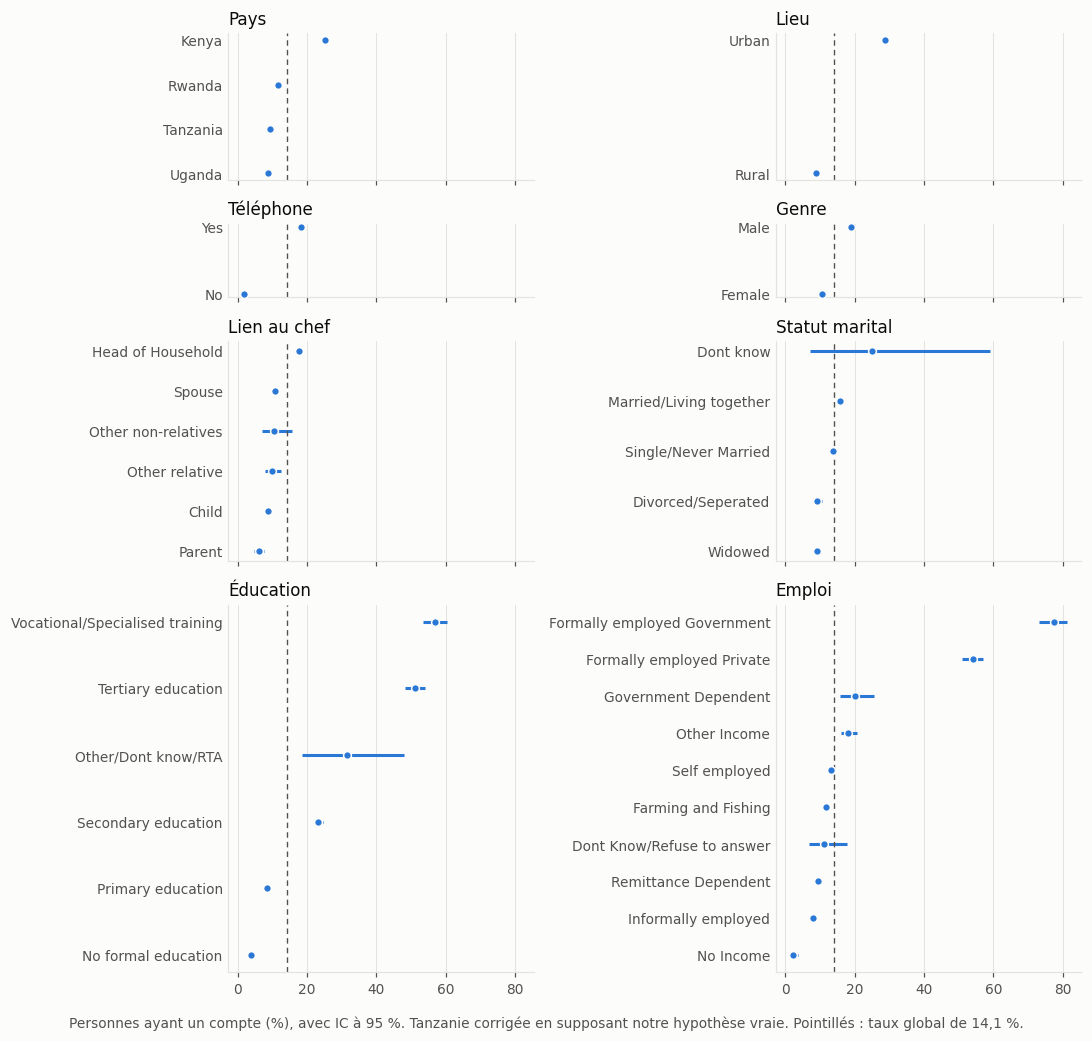

In [29]:
fig, axes = plt.subplots(4, 2, figsize=(10, 9.5), sharex=True, gridspec_kw={"height_ratios": [4, 2, 6, 10]})
global_ = train["compte"].mean()

for variable, ax in zip(categorielles, axes.ravel()):
    taux = taux_par_modalite(train, variable)
    positions = range(len(taux))
    ax.hlines(positions, taux["bas"] * 100, taux["haut"] * 100, color=BLEU, linewidth=2)
    ax.scatter(taux["taux"] * 100, positions, color=BLEU, s=26, zorder=3, edgecolor=FOND, linewidth=1)
    ax.axvline(global_ * 100, color=TEXTE_2, linewidth=0.9, linestyle=(0, (4, 3)))
    ax.set_yticks(list(positions), taux.index.astype(str))
    ax.set_title(noms[variable])
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)

fig.supxlabel("Personnes ayant un compte (%), avec IC à 95 %. Tanzanie corrigée en supposant notre hypothèse vraie. Pointillés : taux global de 14,1 %.", color=TEXTE_2, fontsize=9)
fig.tight_layout()
plt.show()

Les écarts sont très marqués :

- **Éducation :** de 3,9 % sans éducation formelle à 57,0 % en formation professionnelle. Le taux ne suit pas strictement le niveau : `Vocational` dépasse `Tertiary`, ce qui peut venir du signal suspect en Tanzanie.
- **Emploi :** de 2,1 % sans revenu à 77,5 % dans la fonction publique. Seuls les emplois formels sont très au-dessus du reste.
- **Lieu :** 28,9 % en zone urbaine, 8,8 % en zone rurale, en supposant notre hypothèse vraie.
- **Téléphone :** 18,4 % avec un téléphone, 1,7 % sans.
- **Genre :** 19,0 % chez les hommes, 10,7 % chez les femmes.
- **Pays :** 25,1 % au Kenya, contre 8,6 % à 11,5 % ailleurs.

Les intervalles larges sur `Dont know` et `Other/Dont know/RTA` rappellent que ces groupes sont trop petits pour conclure.

### 4.5 Variables numériques face à la cible

Le test de Welch compare les moyennes et le test de Mann-Whitney compare les distributions. Les découpages en tranches servent ensuite à repérer une relation qui ne serait pas monotone.

,moyenne_avec,moyenne_sans,mediane_avec,mediane_sans,t_welch,p_welch,p_mann_whitney,d_cohen
variable,,,,,,,,
age_of_respondent,39.5981,38.6753,36.0,35.0,3.3464,0.0008,0.0,0.0590
household_size,3.6416,3.8230,3.0,3.0,-4.4267,0.0000,0.0,-0.0822


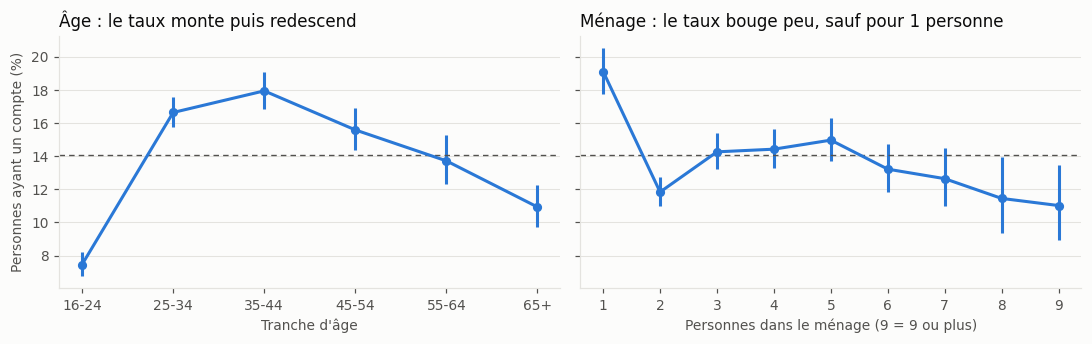

tranche_age x compte : khi-deux = 291.9, ddl = 5, p = 5.42e-61, V = 0.110
menage_borne x compte : khi-deux = 101.5, ddl = 8, p = 2.08e-18, V = 0.063


In [30]:
lignes = []
for variable in numeriques:
    avec, sans = train.loc[train["compte"] == 1, variable], train.loc[train["compte"] == 0, variable]
    welch = stats.ttest_ind(avec, sans, equal_var=False)
    ecart_type = np.sqrt((avec.var() + sans.var()) / 2)
    lignes.append({
        "variable": variable, "moyenne_avec": avec.mean(), "moyenne_sans": sans.mean(),
        "mediane_avec": avec.median(), "mediane_sans": sans.median(),
        "t_welch": welch.statistic, "p_welch": welch.pvalue,
        "p_mann_whitney": stats.mannwhitneyu(avec, sans).pvalue,
        "d_cohen": (avec.mean() - sans.mean()) / ecart_type,
    })
display(pd.DataFrame(lignes).set_index("variable").round(4))

train["tranche_age"] = pd.cut(train["age_of_respondent"], [15, 24, 34, 44, 54, 64, 100],
                              labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"])
train["menage_borne"] = train["household_size"].clip(upper=9)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, variable, titre, etiquette in [
    (axes[0], "tranche_age", "Âge : le taux monte puis redescend", "Tranche d'âge"),
    (axes[1], "menage_borne", "Ménage : le taux bouge peu, sauf pour 1 personne", "Personnes dans le ménage (9 = 9 ou plus)"),
]:
    taux = taux_par_modalite(train, variable).sort_index()
    x = taux.index.astype(str)
    ax.errorbar(x, taux["taux"] * 100, yerr=[(taux["taux"] - taux["bas"]) * 100, (taux["haut"] - taux["taux"]) * 100],
                color=BLEU, linewidth=2, marker="o", markersize=5, capsize=0)
    ax.axhline(train["compte"].mean() * 100, color=TEXTE_2, linewidth=0.9, linestyle=(0, (4, 3)))
    ax.set_title(titre)
    ax.set_xlabel(etiquette)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Personnes ayant un compte (%)")
fig.tight_layout()
plt.show()

for variable in ["tranche_age", "menage_borne"]:
    khi2, p, ddl, v, _ = v_cramer(pd.crosstab(train[variable], train["compte"]))
    print(f"{variable} x compte : khi-deux = {khi2:.1f}, ddl = {ddl}, p = {p:.2e}, V = {v:.3f}")

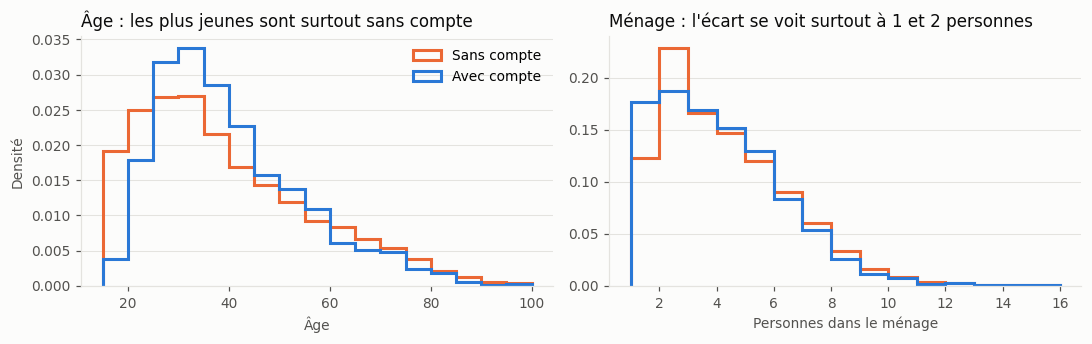

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, variable, bornes, titre, etiquette in [
    (axes[0], "age_of_respondent", range(15, 101, 5), "Âge : les plus jeunes sont surtout sans compte", "Âge"),
    (axes[1], "household_size", range(1, 17), "Ménage : l'écart se voit surtout à 1 et 2 personnes", "Personnes dans le ménage"),
]:
    for valeur, couleur, nom in [(0, ORANGE, "Sans compte"), (1, BLEU, "Avec compte")]:
        ax.hist(train.loc[train["compte"] == valeur, variable], bins=bornes, density=True, histtype="step",
                color=couleur, linewidth=2, label=nom)
    ax.set_title(titre)
    ax.set_xlabel(etiquette)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Densité")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

**Le test de moyenne cache l'essentiel pour l'âge.** Le d de Cohen de 0,06 suggère un lien presque nul, alors que le taux passe de 7,5 % à 18 % puis retombe à 11 %. Le test sur les tranches donne un V de 0,11, contre un effet de 0,075 au test de rangs. Le lien existe bien, mais il est en cloche.

La taille du ménage a l'effet le plus faible de toutes les variables. Le bond à 1 personne ne vaut pas partout, comme le montre la section 4.7.

### 4.6 Les liens tiennent-ils à l'intérieur de chaque pays ?

Pour une variable binaire, on compare l'odds ratio brut à celui de Mantel-Haenszel, qui fixe le pays. Le test CMH vérifie s'il reste un lien, et le test de Breslow-Day (`p_homogeneite`) vérifie si l'odds ratio est le même d'un pays à l'autre.

Un odds ratio de 2 signifie que les chances d'avoir un compte sont deux fois plus élevées. Ce n'est pas une probabilité deux fois plus élevée.

In [32]:
binaires = [("cellphone_access", "Yes"), ("gender_of_respondent", "Male"), ("location_type", "Urban")]
par_pays = pd.DataFrame({
    (v, c): {"or": rapport(tableau_2x2(g, v, m))} for v, m in binaires for c, g in train.groupby("country")
}).T["or"].unstack().round(2)
display(par_pays)

pd.DataFrame({v: stratifier(train, v, m, "country") for v, m in binaires}).T.round({"or_brut": 2, "or_mh": 2, "ic_bas": 2, "ic_haut": 2})

,Kenya,Rwanda,Tanzania,Uganda
cellphone_access,8.64,12.13,36.03,8.29
gender_of_respondent,1.85,2.00,2.25,1.76
location_type,2.67,4.93,5.16,5.55


,or_brut,or_mh,ic_bas,ic_haut,p_cmh,p_homogeneite,strates
cellphone_access,12.92,12.39,10.15,15.11,0.0,1.853130e-05,4.0
gender_of_respondent,1.96,1.97,1.82,2.12,0.0,2.701801e-01,4.0
location_type,4.20,3.73,3.44,4.04,0.0,9.481305e-14,4.0


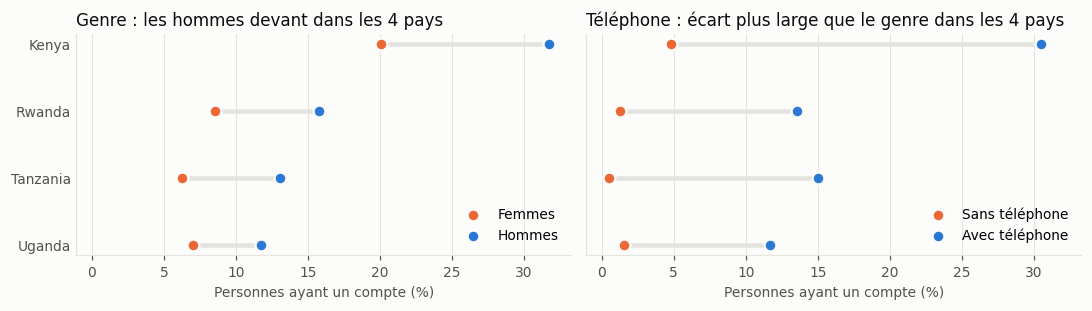

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.9), sharex=True, sharey=True)
for ax, variable, basse, haute, nom_basse, nom_haute, titre in [
    (axes[0], "gender_of_respondent", "Female", "Male", "Femmes", "Hommes", "Genre : les hommes devant dans les 4 pays"),
    (axes[1], "cellphone_access", "No", "Yes", "Sans téléphone", "Avec téléphone", "Téléphone : écart plus large que le genre dans les 4 pays"),
]:
    taux = train.pivot_table(index="country", columns=variable, values="compte", aggfunc="mean").loc[ordre_pays] * 100
    positions = range(len(taux))[::-1]
    ax.hlines(positions, taux[basse], taux[haute], color=GRILLE, linewidth=3, zorder=1)
    ax.scatter(taux[basse], positions, color=ORANGE, s=60, zorder=3, label=nom_basse, edgecolor=FOND, linewidth=1.5)
    ax.scatter(taux[haute], positions, color=BLEU, s=60, zorder=3, label=nom_haute, edgecolor=FOND, linewidth=1.5)
    ax.set_yticks(list(positions), taux.index)
    ax.set_title(titre)
    ax.set_xlabel("Personnes ayant un compte (%)")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

- **Genre :** l'odds ratio est stable, entre 1,76 et 2,25, et le test d'homogénéité ne le rejette pas (p = 0,27). L'écart entre genres est le résultat le plus régulier de l'analyse.
- **Téléphone :** le lien est fort partout, mais son intensité varie : de 8,3 en Ouganda à 36,0 en Tanzanie.
- **Lieu :** sous notre hypothèse, il va dans le même sens dans les quatre pays. Il vaut 2,67 au Kenya et de 4,93 à 5,55 ailleurs, et le test d'homogénéité rejette l'égalité entre pays.

### 4.7 Force des liens dans chaque pays

Le tableau donne le V de Cramér de chaque variable avec la cible, pays par pays.

In [34]:
tableau_v = pd.DataFrame({
    pays: {noms[v]: v_cramer(pd.crosstab(g[v], g["compte"]))[3] for v in categorielles if v != "country"}
    for pays, g in train.groupby("country")
})[ordre_pays]
tableau_v.loc["Âge (tranches)"] = [v_cramer(pd.crosstab(train[train["country"] == p]["tranche_age"], train[train["country"] == p]["compte"]))[3] for p in ordre_pays]
tableau_v.loc["Ménage (borné)"] = [v_cramer(pd.crosstab(train[train["country"] == p]["menage_borne"], train[train["country"] == p]["compte"]))[3] for p in ordre_pays]
tableau_v.round(3)

,Kenya,Rwanda,Tanzania,Uganda
Lieu,0.211,0.247,0.245,0.248
Téléphone,0.241,0.145,0.247,0.164
Genre,0.132,0.110,0.116,0.077
Lien au chef,0.163,0.066,0.137,0.084
Statut marital,0.088,0.089,0.068,0.050
Éducation,0.399,0.352,0.464,0.466
Emploi,0.407,0.307,0.469,0.354
Âge (tranches),0.128,0.119,0.111,0.092
Ménage (borné),0.146,0.037,0.035,0.000


L'éducation et l'emploi restent les liens les plus forts dans les quatre pays. L'ordre des variables est donc robuste. Sous notre hypothèse, le lien du lieu est aussi très proche d'un pays à l'autre, de 0,21 à 0,25.

Le bond observé pour les ménages d'une personne n'est pas général : le V de la taille du ménage vaut 0,15 au Kenya, mais moins de 0,04 ailleurs. Ce lien vient donc surtout d'un seul pays.

### 4.8 Tester les variables de confusion

Si l'emploi ou l'éducation expliquait à lui seul le lien avec le téléphone, l'odds ratio tomberait vers 1 une fois ces variables fixées. Le même raisonnement vaut pour le genre. Les strates sans effectif suffisant sont écartées.

In [35]:
train["pays_education"] = train["country"] + " / " + train["education_level"]
train["pays_emploi"] = train["country"] + " / " + train["job_type"]
train["emploi_education"] = train["job_type"] + " / " + train["education_level"]

scenarios = [
    ("cellphone_access", "Yes", "country"), ("cellphone_access", "Yes", "job_type"), ("cellphone_access", "Yes", "education_level"),
    ("cellphone_access", "Yes", "pays_education"), ("cellphone_access", "Yes", "emploi_education"),
    ("gender_of_respondent", "Male", "country"), ("gender_of_respondent", "Male", "job_type"), ("gender_of_respondent", "Male", "education_level"),
    ("gender_of_respondent", "Male", "relationship_with_head"), ("gender_of_respondent", "Male", "pays_education"),
    ("gender_of_respondent", "Male", "emploi_education"),
]
pd.DataFrame([
    {"variable": noms[v], "fixee": strate, **stratifier(train, v, m, strate)} for v, m, strate in scenarios
]).round({"or_brut": 2, "or_mh": 2, "ic_bas": 2, "ic_haut": 2}).assign(
    p_cmh=lambda t: t["p_cmh"].map("{:.1e}".format), p_homogeneite=lambda t: t["p_homogeneite"].map("{:.3f}".format))

,variable,fixee,or_brut,or_mh,ic_bas,ic_haut,p_cmh,p_homogeneite,strates
0,Téléphone,country,12.92,12.39,10.15,15.11,0.0e+00,0.000,4
1,Téléphone,job_type,12.92,10.84,8.83,13.30,0.0e+00,0.000,10
2,Téléphone,education_level,12.92,8.61,7.03,10.56,0.0e+00,0.000,6
3,Téléphone,pays_education,12.92,7.50,6.11,9.21,0.0e+00,0.000,21
4,Téléphone,emploi_education,12.92,7.42,6.00,9.18,0.0e+00,0.000,48
5,Genre,country,1.96,1.97,1.82,2.12,0.0e+00,0.270,4
6,Genre,job_type,1.96,1.85,1.70,2.00,0.0e+00,0.000,10
7,Genre,education_level,1.96,1.77,1.63,1.92,0.0e+00,0.257,6
8,Genre,relationship_with_head,1.96,1.83,1.67,2.00,0.0e+00,0.004,6
9,Genre,pays_education,1.96,1.78,1.64,1.93,0.0e+00,0.172,23


- **Téléphone :** l'odds ratio passe de 12,9 à 7,4 en fixant l'emploi et l'éducation. Ces variables expliquent donc une partie du lien, mais il reste très fort.
- **Genre :** il passe de 1,96 à 1,69. Le profil observé n'explique qu'une petite partie de l'écart.

Ce n'est pas la preuve d'un effet causal : une variable absente du jeu de données, comme le revenu, peut encore expliquer le reste. On peut seulement dire que **les variables disponibles n'effacent pas ces liens**.

Lorsque `p_homogeneite` est faible, l'odds ratio commun est une moyenne de situations différentes. Il faut alors regarder les strates, comme ci-dessous pour l'emploi.

In [36]:
train.pivot_table(index="job_type", columns="cellphone_access", values="compte", aggfunc=["mean", "size"]).round(3)

mean         size      
cellphone_access                 No    Yes    No   Yes
job_type                                              
Dont Know/Refuse to answer    0.000  0.147    31    95
Farming and Fishing           0.033  0.134   918  4523
Formally employed Government  0.667  0.777     6   381
Formally employed Private     0.064  0.563    47  1008
Government Dependent          0.120  0.287   125   122
Informally employed           0.007  0.106  1481  4116
No Income                     0.006  0.038   334   293
Other Income                  0.034  0.236   293   787
Remittance Dependent          0.014  0.141   917  1610
Self employed                 0.009  0.184  1918  4519

Dans presque tous les emplois, l'écart lié au téléphone subsiste. La ligne `Formally employed Government` n'est pas exploitable du côté `No`, avec seulement 6 personnes.

### 4.9 Variables relais et âge

In [37]:
relais = pd.crosstab(train["relationship_with_head"], train["gender_of_respondent"], normalize="index").round(3)
relais["effectif"] = train["relationship_with_head"].value_counts()
display(relais)

age_emploi = train.pivot_table(index="tranche_age", columns="education_level", values="compte", aggfunc="mean", observed=True).round(3)
display(age_emploi)
print("Part de l'enseignement après le primaire par tranche d'âge :")
print(train.groupby("tranche_age", observed=True)["apres_primaire"].mean().round(3).to_string())

gender_of_respondent,Female,Male,effectif
relationship_with_head,,,
Child,0.525,0.475,2229
Head of Household,0.404,0.596,12831
Other non-relatives,0.584,0.416,190
Other relative,0.555,0.445,668
Parent,0.565,0.435,1086
Spouse,0.986,0.014,6520


education_level,No formal education,Other/Dont know/RTA,Primary education,Secondary education,Tertiary education,Vocational/Specialised training
tranche_age,,,,,,
16-24,0.021,0.00,0.030,0.083,0.291,0.314
25-34,0.027,0.40,0.080,0.301,0.502,0.647
35-44,0.027,0.40,0.113,0.355,0.696,0.634
45-54,0.032,0.50,0.102,0.340,0.705,0.598
55-64,0.039,0.25,0.112,0.350,0.860,0.642
65+,0.062,0.30,0.108,0.420,0.615,0.533


Part de l'enseignement après le primaire par tranche d'âge :
tranche_age
16-24    0.448
25-34    0.283
35-44    0.231
45-54    0.202
55-64    0.144
65+      0.069


**Le genre a un relais direct :** 98,6 % des `Spouse` sont des femmes. Retirer le genre n'empêcherait donc pas de le retrouver à travers cette variable.

**L'éducation n'explique pas la cloche de l'âge :** à niveau d'éducation fixé, les 16-24 ans ont nettement moins de comptes (8,3 % contre 30,1 % pour les 25-34 ans en secondaire), alors que ce sont eux qui ont le plus souvent dépassé le primaire. Âge et éducation doivent donc être lus ensemble.

## 5. Analyse multivariée

**Rappel :** ces résultats supposent vraie notre hypothèse sur les libellés de Tanzanie (section 3.7). Aucune documentation du jeu de données ne la confirme.

### 5.1 ACP

Une ACP ne s'applique qu'aux variables numériques, et le jeu de données n'en a que deux.

In [38]:
donnees_num = train[numeriques]
centrees = (donnees_num - donnees_num.mean()) / donnees_num.std()
valeurs, vecteurs = np.linalg.eigh(np.corrcoef(centrees.T))
ordre = valeurs.argsort()[::-1]
valeurs, vecteurs = valeurs[ordre], vecteurs[:, ordre]

print("Corrélation de Pearson âge-ménage :", round(centrees.corr().iloc[0, 1], 3))
display(pd.DataFrame({"valeur_propre": valeurs, "part": valeurs / valeurs.sum()}, index=["PC1", "PC2"]).round(3))
pd.DataFrame(vecteurs, index=numeriques, columns=["PC1", "PC2"]).round(3)

Corrélation de Pearson âge-ménage : -0.13


,valeur_propre,part
PC1,1.13,0.565
PC2,0.87,0.435


,PC1,PC2
age_of_respondent,-0.707,-0.707
household_size,0.707,-0.707


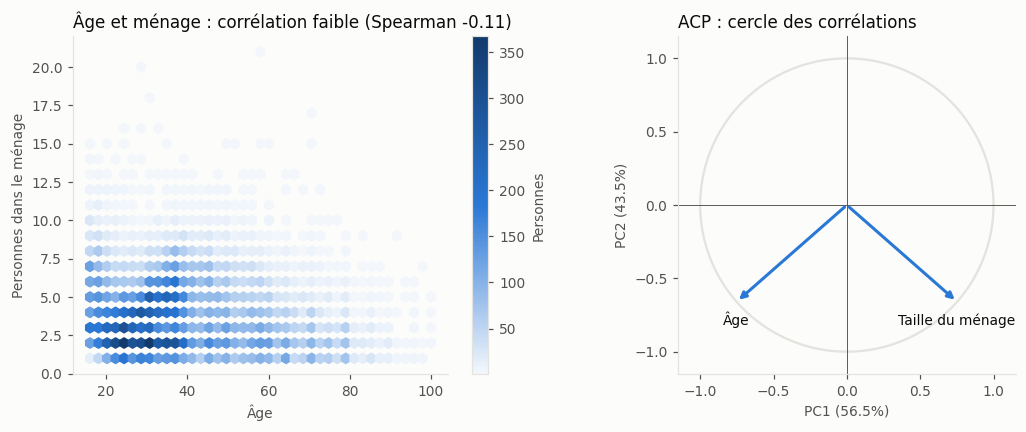

In [39]:
rho = stats.spearmanr(train["age_of_respondent"], train["household_size"]).statistic
coordonnees_acp = vecteurs * np.sqrt(valeurs)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

image = axes[0].hexbin(train["age_of_respondent"], train["household_size"], gridsize=(40, 20), cmap=RAMPE, mincnt=1)
axes[0].set_title(f"Âge et ménage : corrélation faible (Spearman {rho:.2f})")
axes[0].set_xlabel("Âge")
axes[0].set_ylabel("Personnes dans le ménage")
axes[0].grid(False)
fig.colorbar(image, ax=axes[0], label="Personnes")

angles = np.linspace(0, 2 * np.pi, 200)
axes[1].plot(np.cos(angles), np.sin(angles), color=GRILLE, linewidth=1.5)
axes[1].axhline(0, color=TEXTE_2, linewidth=0.6)
axes[1].axvline(0, color=TEXTE_2, linewidth=0.6)
for nom_variable, (x, y) in zip(["Âge", "Taille du ménage"], coordonnees_acp):
    axes[1].annotate("", (x, y), (0, 0), arrowprops={"arrowstyle": "-|>", "color": BLEU, "linewidth": 2})
    axes[1].annotate(nom_variable, (x, y), xytext=(0, 9 if y > 0 else -15), textcoords="offset points", color=TEXTE, ha="center")
axes[1].set_xlim(-1.15, 1.15)
axes[1].set_ylim(-1.15, 1.15)
axes[1].set_aspect("equal")
axes[1].set_xlabel(f"PC1 ({valeurs[0] / valeurs.sum():.1%})")
axes[1].set_ylabel(f"PC2 ({valeurs[1] / valeurs.sum():.1%})")
axes[1].set_title("ACP : cercle des corrélations")
axes[1].grid(False)
fig.tight_layout()
plt.show()

L'ACP est faite, mais elle n'apprend presque rien : avec une corrélation de -0,13, les deux axes valent 56,5 % et 43,5 %. Deux variables presque indépendantes ne se résument pas. Le cercle le montre : PC1 oppose l'âge à la taille du ménage, et PC2 les combine. L'analyse adaptée à ce jeu de données est l'ACM, ou l'AFDM pour les variables mixtes.

### 5.2 ACM

L'ACM est l'équivalent de l'ACP pour les variables catégorielles. Elle porte sur les 8 variables catégorielles, plus l'âge et le ménage en tranches. Les modalités très rares sont regroupées pour ne pas dominer les axes. **La cible ne participe pas au calcul des axes** : elle est seulement projetée ensuite.

Dans une ACM, de petits pourcentages d'inertie sont normaux, car le découpage en modalités les fait chuter. Le repère utile est la moyenne attendue par axe.

In [40]:
def preparer_qualitatives(donnees):
    """Regroupe les modalités rares et découpe les numériques : l'ACM ne lit que des catégories."""
    table = regrouper_rares(donnees)[categorielles]
    table["age"] = pd.cut(donnees["age_of_respondent"], [15, 24, 34, 44, 54, 64, 100],
                          labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"]).astype(object)
    table["menage"] = pd.cut(donnees["household_size"], [0, 1, 3, 5, 30], labels=["1", "2-3", "4-5", "6+"]).astype(object)
    return table.astype(object)


def lancer_acm(donnees):
    table = preparer_qualitatives(donnees)
    return table, prince.MCA(n_components=6, random_state=0, correction=None).fit(table)


acm_table, acm = lancer_acm(train)

pd.DataFrame({"inertie": np.round(acm.percentage_of_variance_[:6], 2)}, index=[f"axe {i}" for i in range(1, 7)]).assign(
    moyenne_attendue=round(100 / (acm_table.apply(pd.Series.nunique).sum() - acm_table.shape[1]), 2))

,inertie,moyenne_attendue
axe 1,7.90,2.94
axe 2,6.26,2.94
axe 3,6.05,2.94
axe 4,5.61,2.94
axe 5,4.58,2.94
axe 6,4.34,2.94


Les trois premiers axes dépassent nettement la moyenne de 2,94 %, mais ils ne dominent pas : l'information est répartie sur de nombreuses dimensions.

In [41]:
contributions = acm.column_contributions_.iloc[:, :3]
meilleures = {
    f"axe {i + 1}": [f"{nom} ({valeur:.1%})" for nom, valeur in contributions.iloc[:, i].nlargest(8).items()]
    for i in range(3)
}
pd.DataFrame(meilleures)

,axe 1,axe 2,axe 3
0,marital_status__Single/Never Married (18.5%),country__Tanzania (12.2%),marital_status__Widowed (12.6%)
1,age__16-24 (15.1%),country__Rwanda (10.1%),age__65+ (9.4%)
2,relationship_with_head__Child (11.3%),menage__1 (9.8%),job_type__Self employed (6.9%)
3,education_level__Secondary education (6.7%),job_type__Farming and Fishing (8.8%),education_level__No formal education (6.7%)
4,education_level__No formal education (5.1%),relationship_with_head__Spouse (5.4%),marital_status__Married/Living together (6.1%)
5,marital_status__Widowed (4.9%),menage__6+ (5.3%),relationship_with_head__Child (5.8%)
6,age__65+ (3.8%),menage__4-5 (4.2%),country__Tanzania (5.2%)
7,relationship_with_head__Head of Household (3.6%),job_type__Self employed (3.9%),relationship_with_head__Spouse (5.1%)


- **Axe 1 :** c'est un axe de cycle de vie, des jeunes célibataires encore enfants du chef jusqu'aux personnes âgées et veuves, avec l'éducation.
- **Axe 2 :** il oppose surtout la Tanzanie au Rwanda, avec la taille du ménage et l'agriculture.
- **Axe 3 :** il croise veuvage, grand âge, travail indépendant et absence d'éducation formelle.

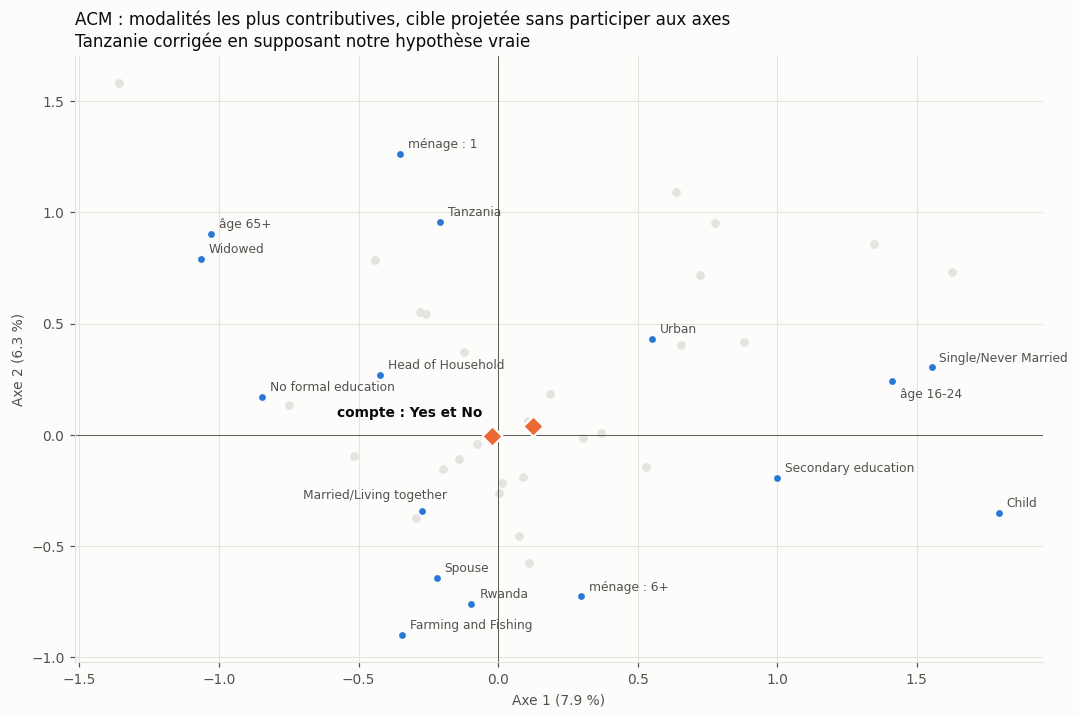

,axe1,axe2,axe3
r_compte,0.097,0.032,-0.150
eta2_pays,0.042,0.476,0.232


In [42]:
coordonnees = acm.column_coordinates(acm_table).iloc[:, :2]
coordonnees.columns = ["axe1", "axe2"]
lignes_acm = acm.row_coordinates(acm_table).iloc[:, :2]
lignes_acm.columns = ["axe1", "axe2"]
inertie = acm.percentage_of_variance_[:2]

a_nommer = contributions.iloc[:, :2].sum(axis=1).nlargest(16).index

fig, ax = plt.subplots(figsize=(10, 6.6))
ax.scatter(coordonnees["axe1"], coordonnees["axe2"], color=GRILLE, s=22, zorder=2)
selection = coordonnees.loc[a_nommer]
ax.scatter(selection["axe1"], selection["axe2"], color=BLEU, s=30, zorder=3, edgecolor=FOND, linewidth=1)
decalages = {"country__Rwanda": (6, 4), "age__16-24": (5, -11), "marital_status__Married/Living together": (-78, 8), "location_type__Rural": (5, -12)}
prefixes = {"age": "âge ", "menage": "ménage : "}
for nom, ligne in selection.iterrows():
    variable, modalite = nom.split("__")
    ax.annotate(prefixes.get(variable, "") + modalite, (ligne["axe1"], ligne["axe2"]), xytext=decalages.get(nom, (5, 4)),
                textcoords="offset points", fontsize=8, color=TEXTE_2)

barycentres = lignes_acm.groupby(train["bank_account"]).mean()
ax.scatter(barycentres["axe1"], barycentres["axe2"], color=ORANGE, s=90, marker="D", zorder=4, edgecolor=FOND, linewidth=1.5)
ax.annotate("compte : Yes et No", (0, 0), xytext=(-10, 12), textcoords="offset points", fontsize=9, color=TEXTE, weight="bold", ha="right")

ax.axhline(0, color=TEXTE_2, linewidth=0.6)
ax.axvline(0, color=TEXTE_2, linewidth=0.6)
ax.set_xlabel(f"Axe 1 ({inertie[0]:.1f} %)")
ax.set_ylabel(f"Axe 2 ({inertie[1]:.1f} %)")
ax.set_title("ACM : modalités les plus contributives, cible projetée sans participer aux axes\nTanzanie corrigée en supposant notre hypothèse vraie")
fig.tight_layout()
plt.show()

axes_acm = acm.row_coordinates(acm_table).iloc[:, :3]
axes_acm.columns = ["axe1", "axe2", "axe3"]


def eta2(axe, groupes):
    """Part de la variance d'un axe expliquée par des groupes."""
    moyennes = axe.groupby(groupes).transform("mean")
    return ((moyennes - axe.mean()) ** 2).sum() / ((axe - axe.mean()) ** 2).sum()


pd.DataFrame({
    axe: {"r_compte": stats.pointbiserialr(train["compte"], axes_acm[axe])[0], "eta2_pays": eta2(axes_acm[axe], train["country"])}
    for axe in axes_acm.columns
}).round(3)

**Le résultat important est ici : aucun des trois premiers axes ne résume la cible.** L'axe 1 suit le cycle de vie, avec r = 0,10 avec le compte. L'axe 2 est expliqué à 48 % par le pays, avec r = 0,03. Le lien le plus net est sur l'axe 3, et il reste faible (r = -0,15). C'est pourquoi les deux losanges sont proches sur le graphique.

Une valeur-test mesure l'écart d'un groupe au centre de l'axe. Au-delà de 2 en valeur absolue, cet écart n'est pas dû au hasard.

In [43]:
def valeur_test(axe, masque):
    """Écart du groupe au centre de l'axe, en écarts-types. Au-delà de 2, il n'est pas dû au hasard."""
    n, n_groupe = len(axe), masque.sum()
    return axe[masque].mean() / np.sqrt(axe.var() * (n - n_groupe) / (n_groupe * (n - 1)))


pd.DataFrame({
    axe: {
        "compte = Yes": valeur_test(axes_acm[axe], train["bank_account"] == "Yes"),
        **{f"pays = {p}": valeur_test(axes_acm[axe], train["country"] == p) for p in ordre_pays},
    }
    for axe in axes_acm.columns
}).round(1)

,axe1,axe2,axe3
compte = Yes,14.9,5.0,-22.9
pays = Kenya,27.5,-1.4,18.8
pays = Rwanda,-11.6,-89.6,55.2
pays = Tanzania,-19.9,92.0,-59.4
pays = Uganda,8.9,8.8,-28.7


La Tanzanie (92) et le Rwanda (-90) s'opposent très fortement sur l'axe 2. Le compte se lit surtout sur l'axe 3 (-23).

### 5.3 AFDM

L'AFDM traite les numériques et les catégorielles ensemble, sans découper l'âge. Elle généralise l'ACP aux données mixtes. Elle est écrite ici à partir de sa définition, car `prince` a refusé les variables numériques de ce jeu de données.

,inertie
axe 1,0.0939
axe 2,0.0738
axe 3,0.0661
axe 4,0.0602
axe 5,0.0552
axe 6,0.0520


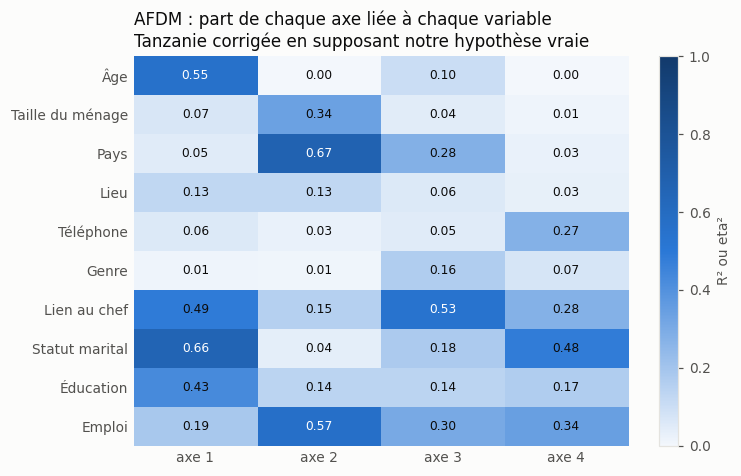

,axe 1,axe 2,axe 3,axe 4,axe 5,axe 6
r_compte,0.141,-0.119,-0.276,-0.305,-0.175,0.005


In [44]:
def lancer_afdm(donnees, composantes=6):
    """AFDM (Pagès) : ACP des numériques réduites et des indicatrices centrées, pondérées par 1 / racine(fréquence)."""
    table = preparer_qualitatives(donnees).drop(columns=["age", "menage"])
    reduites = (donnees[numeriques] - donnees[numeriques].mean()) / donnees[numeriques].std()
    indicatrices = pd.get_dummies(table).astype(float)
    frequences = indicatrices.mean()
    matrice = pd.concat([reduites, (indicatrices - frequences) / np.sqrt(frequences)], axis=1).to_numpy()
    u, s, vt = np.linalg.svd(matrice / np.sqrt(len(matrice)), full_matrices=False)
    scores = pd.DataFrame(u[:, :composantes] * s[:composantes] * np.sqrt(len(matrice)), index=donnees.index,
                          columns=[f"axe {i + 1}" for i in range(composantes)])
    part = s ** 2 / (s ** 2).sum()
    return scores, part[:composantes]


def lien_axes(donnees, scores):
    """Part de chaque axe expliquée par chaque variable : R² pour un nombre, eta² pour une catégorie."""
    table = preparer_qualitatives(donnees).drop(columns=["age", "menage"])
    sortie = {}
    for axe in scores.columns:
        ligne = {v: stats.pearsonr(donnees[v], scores[axe])[0] ** 2 for v in numeriques}
        for v in table.columns:
            moyennes = scores[axe].groupby(table[v]).transform("mean")
            ligne[v] = ((moyennes - scores[axe].mean()) ** 2).sum() / ((scores[axe] - scores[axe].mean()) ** 2).sum()
        sortie[axe] = ligne
    return pd.DataFrame(sortie).rename(index=noms)


scores_afdm, part_afdm = lancer_afdm(train)

display(pd.DataFrame({"inertie": part_afdm}, index=scores_afdm.columns).round(4))
carte_afdm = lien_axes(train, scores_afdm).iloc[:, :4]

fig, ax = plt.subplots(figsize=(7, 4.4))
image = ax.imshow(carte_afdm.values, cmap=RAMPE, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(4), carte_afdm.columns)
ax.set_yticks(range(len(carte_afdm)), carte_afdm.index)
ax.grid(False)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
for i, j in itertools.product(range(carte_afdm.shape[0]), range(4)):
    valeur = carte_afdm.values[i, j]
    ax.text(j, i, f"{valeur:.2f}", ha="center", va="center", fontsize=8, color="white" if valeur > 0.5 else TEXTE)
ax.set_title("AFDM : part de chaque axe liée à chaque variable\nTanzanie corrigée en supposant notre hypothèse vraie")
fig.colorbar(image, label="R² ou eta²")
fig.tight_layout()
plt.show()

pd.DataFrame({axe: {"r_compte": stats.pointbiserialr(train["compte"], scores_afdm[axe])[0]} for axe in scores_afdm.columns}).round(3)

L'AFDM confirme l'ACM :

- L'axe 1 (9,4 %) suit le cycle de vie : statut marital, âge, lien au chef et éducation.
- L'axe 2 (7,4 %) est lié au pays, à l'emploi et à la taille du ménage.
- L'axe 3 (6,6 %) est lié au lien au chef et à l'emploi (r = -0,28 avec la cible).
- L'axe 4 (6,0 %) est lié au statut marital, à l'emploi et au téléphone, et c'est le plus corrélé à la cible (r = -0,31).

Aucun petit nombre d'axes ne résume les données, puisque six axes en couvrent environ 40 %.

## 6. Décisions pour la modélisation

Ces décisions découlent uniquement de l'EDA. Elles s'appuient sur des associations observées dans ce jeu de données, pas sur des causes.

**La correction de la Tanzanie n'est plus une décision à prendre.** Elle est appliquée, et toutes les décisions ci-dessous supposent vraie notre hypothèse sur les libellés.

In [45]:
accuracy_naive = 1 - train["compte"].mean()
f1_non = 2 * accuracy_naive / (1 + accuracy_naive)
print(f"Référence naïve, calcul direct : accuracy = {accuracy_naive:.4f}, F1 macro = {f1_non / 2:.4f}")
print(f"Lignes rares : {(train['marital_status'] == 'Dont know').sum()} Dont know, "
      f"{(train['education_level'] == 'Other/Dont know/RTA').sum()} Other/Dont know/RTA, "
      f"{(train['relationship_with_head'] == 'Other non-relatives').sum()} Other non-relatives")
print(f"Lignes contradictoires : {memes_profils.sum()} ({memes_profils.mean():.1%} du train)")

Référence naïve, calcul direct : accuracy = 0.8592, F1 macro = 0.4621
Lignes rares : 8 Dont know, 35 Other/Dont know/RTA, 190 Other non-relatives
Lignes contradictoires : 1746 (7.4% du train)


### Préparation des données

Ces décisions sont appliquées dans `src/preparation.py` et vérifiées dans `02_preparation.ipynb`.

| # | Constat | Décision |
|---|---|---|
| 1 | `uniqueid` n'identifie personne d'un pays à l'autre | Le retirer |
| 2 | `year` recopie le pays | Le retirer et parler de « pays-année » |
| 3 | Tanzanie : `Tertiary` à 32 % et `Vocational` à 73 %, sans preuve indépendante de la cible | Ne pas recoder, et le documenter |
| 4 | Modalités rares (8, 35, 190 et 126 lignes) | Regrouper les trois premières. Garder `Dont Know/Refuse to answer` comme non-réponse |
| 5 | Valeurs extrêmes plausibles | Ne rien retirer |
| 6 | Profils répétés et 1 746 lignes contradictoires (7,4 %) | Garder ces lignes, qui ne sont pas des erreurs. Elles fixent une limite à toute prédiction |
| 7 | Aucune valeur manquante | Pas d'imputation |

### Choix des variables

| # | Constat | Décision |
|---|---|---|
| 8 | Éducation, emploi, lieu, téléphone et pays dominent | Variables prioritaires, et base de l'ajout « moins de questions » |
| 9 | `Vocational` dépasse `Tertiary` | Encoder l'éducation en catégories, pas en échelle ordonnée |
| 10 | L'âge est en cloche et arrondi | Le garder sous une forme qui permet une relation non linéaire, comme des tranches |
| 11 | Taille du ménage : effet le plus faible, porté surtout par le Kenya | La garder au départ, comme première candidate au retrait |
| 12 | Associations fortes (0,62 au plus), mais aucune redondance | Ne retirer aucune variable pour cause de redondance |
| 13 | ACP sans intérêt, ACM et AFDM dispersées, aucun axe fortement lié à la cible | Ne pas donner de composantes au modèle |

### Choix des modèles

| # | Constat | Décision |
|---|---|---|
| 14 | Le lien du téléphone et du lieu varie selon le pays | Tester des modèles capables de capturer des interactions, en plus d'un modèle simple |
| 15 | `job_type` n'a pas les mêmes modalités selon le pays | Vérifier que le modèle n'en tire pas une fausse différence entre pays |

### Évaluation

| # | Constat | Décision |
|---|---|---|
| 16 | Cible à 14,08 % | Découpage stratifié sur la cible et le pays, F1 macro comme métrique principale |
| 17 | Référence naïve : accuracy de 85,92 %, F1 macro de 0,462 | Tout modèle doit battre ces chiffres sur des données qu'il n'a pas vues |
| 18 | Le seuil de 0,5 n'a pas de raison d'être optimal avec ce déséquilibre | Choisir le seuil sur la validation, jamais sur le test final |
| 19 | Écarts forts entre pays | Mesurer les performances par pays, pas seulement au global |

### Genre, pays et application

| # | Constat | Décision |
|---|---|---|
| 20 | 98,6 % des `Spouse` sont des femmes | Garder le genre pour mesurer son poids : le retirer masquerait le problème sans l'enlever. Mesurer aussi les erreurs par genre |
| 21 | Écart entre genres stable, odds ratio de 1,69 après contrôle | L'ajout « autre genre » doit dire qu'il montre la réaction du modèle, pas un effet causal |
| 22 | Pays confondu avec l'année et avec le codage de `job_type` | L'ajout « autre pays » doit porter le même avertissement |
| 23 | Les modalités de `job_type` dépendent du pays | Le formulaire applique les mêmes regroupements, sans corriger la Tanzanie puisque la personne y déclare elle-même ses réponses, et signale les modalités absentes d'un pays |
| 24 | Le KNN mesure une distance sur ces mêmes libellés | Le calculer sur les données préparées, en comparant aussi à l'intérieur du pays |

### Limites de cette EDA

- Tous les constats sont des associations observées dans ce jeu de données.
- **Tout ce qui suit la section 3.8 suppose vraie notre hypothèse sur la Tanzanie.** Aucune documentation du jeu de données ne la confirme. Si elle était fausse, les résultats sur le lieu et le statut marital seraient à revoir.
- Le jeu de données ne contient pas le revenu : une part des liens observés peut venir de variables absentes.
- Le pays, l'année et le mode de codage ne peuvent pas être séparés.

## 7. Usages retenus pour l'interface

L'interface repose sur un formulaire de profil qui affiche la probabilité d'avoir un compte. Cinq usages s'y ajoutent. Aucun modèle n'a encore été entraîné : ce tableau décrit ce qui est prévu, avec ce que l'EDA impose à chaque usage.

| Usage | Ce que voit la personne | Méthode | Ce que l'EDA impose |
|---|---|---|---|
| Prédiction | La probabilité d'avoir un compte pour le profil saisi | Classification | Battre la référence naïve (F1 macro de 0,462), et garder en tête les 7,4 % de lignes contradictoires |
| Facteurs du score | Les variables qui ont poussé le score vers le haut ou vers le bas | Explication du modèle | Présenter des facteurs du score, pas des causes |
| Même profil, autres pays | La prédiction du même profil dans les trois autres pays | Même modèle, seul le pays change | Signaler les modalités de `job_type` absentes d'un pays. Le pays reste confondu avec l'année et le codage |
| Même profil, autre genre | La prédiction du même profil avec l'autre genre | Même modèle, seul le genre change | Dire que cela montre la réaction du modèle, pas un effet causal. `Spouse` reste un relais du genre (98,6 % de femmes) |
| Personnes similaires | Le taux réel de comptes chez les personnes les plus proches du profil | KNN | Calculer sur les données préparées, et comparer aussi à l'intérieur du pays |
| Moins de questions | La prédiction avec peu de questions, comparée au formulaire complet | Second modèle sur moins de variables | Partir de l'éducation, de l'emploi, du lieu, du téléphone et du pays |

**Dans le formulaire, la Tanzanie n'est pas corrigée**, car la personne y déclare elle-même son lieu et son statut. Les modèles apprennent toutefois sur des données corrigées en supposant notre hypothèse vraie : l'interface doit donc le préciser pour les profils de Tanzanie.